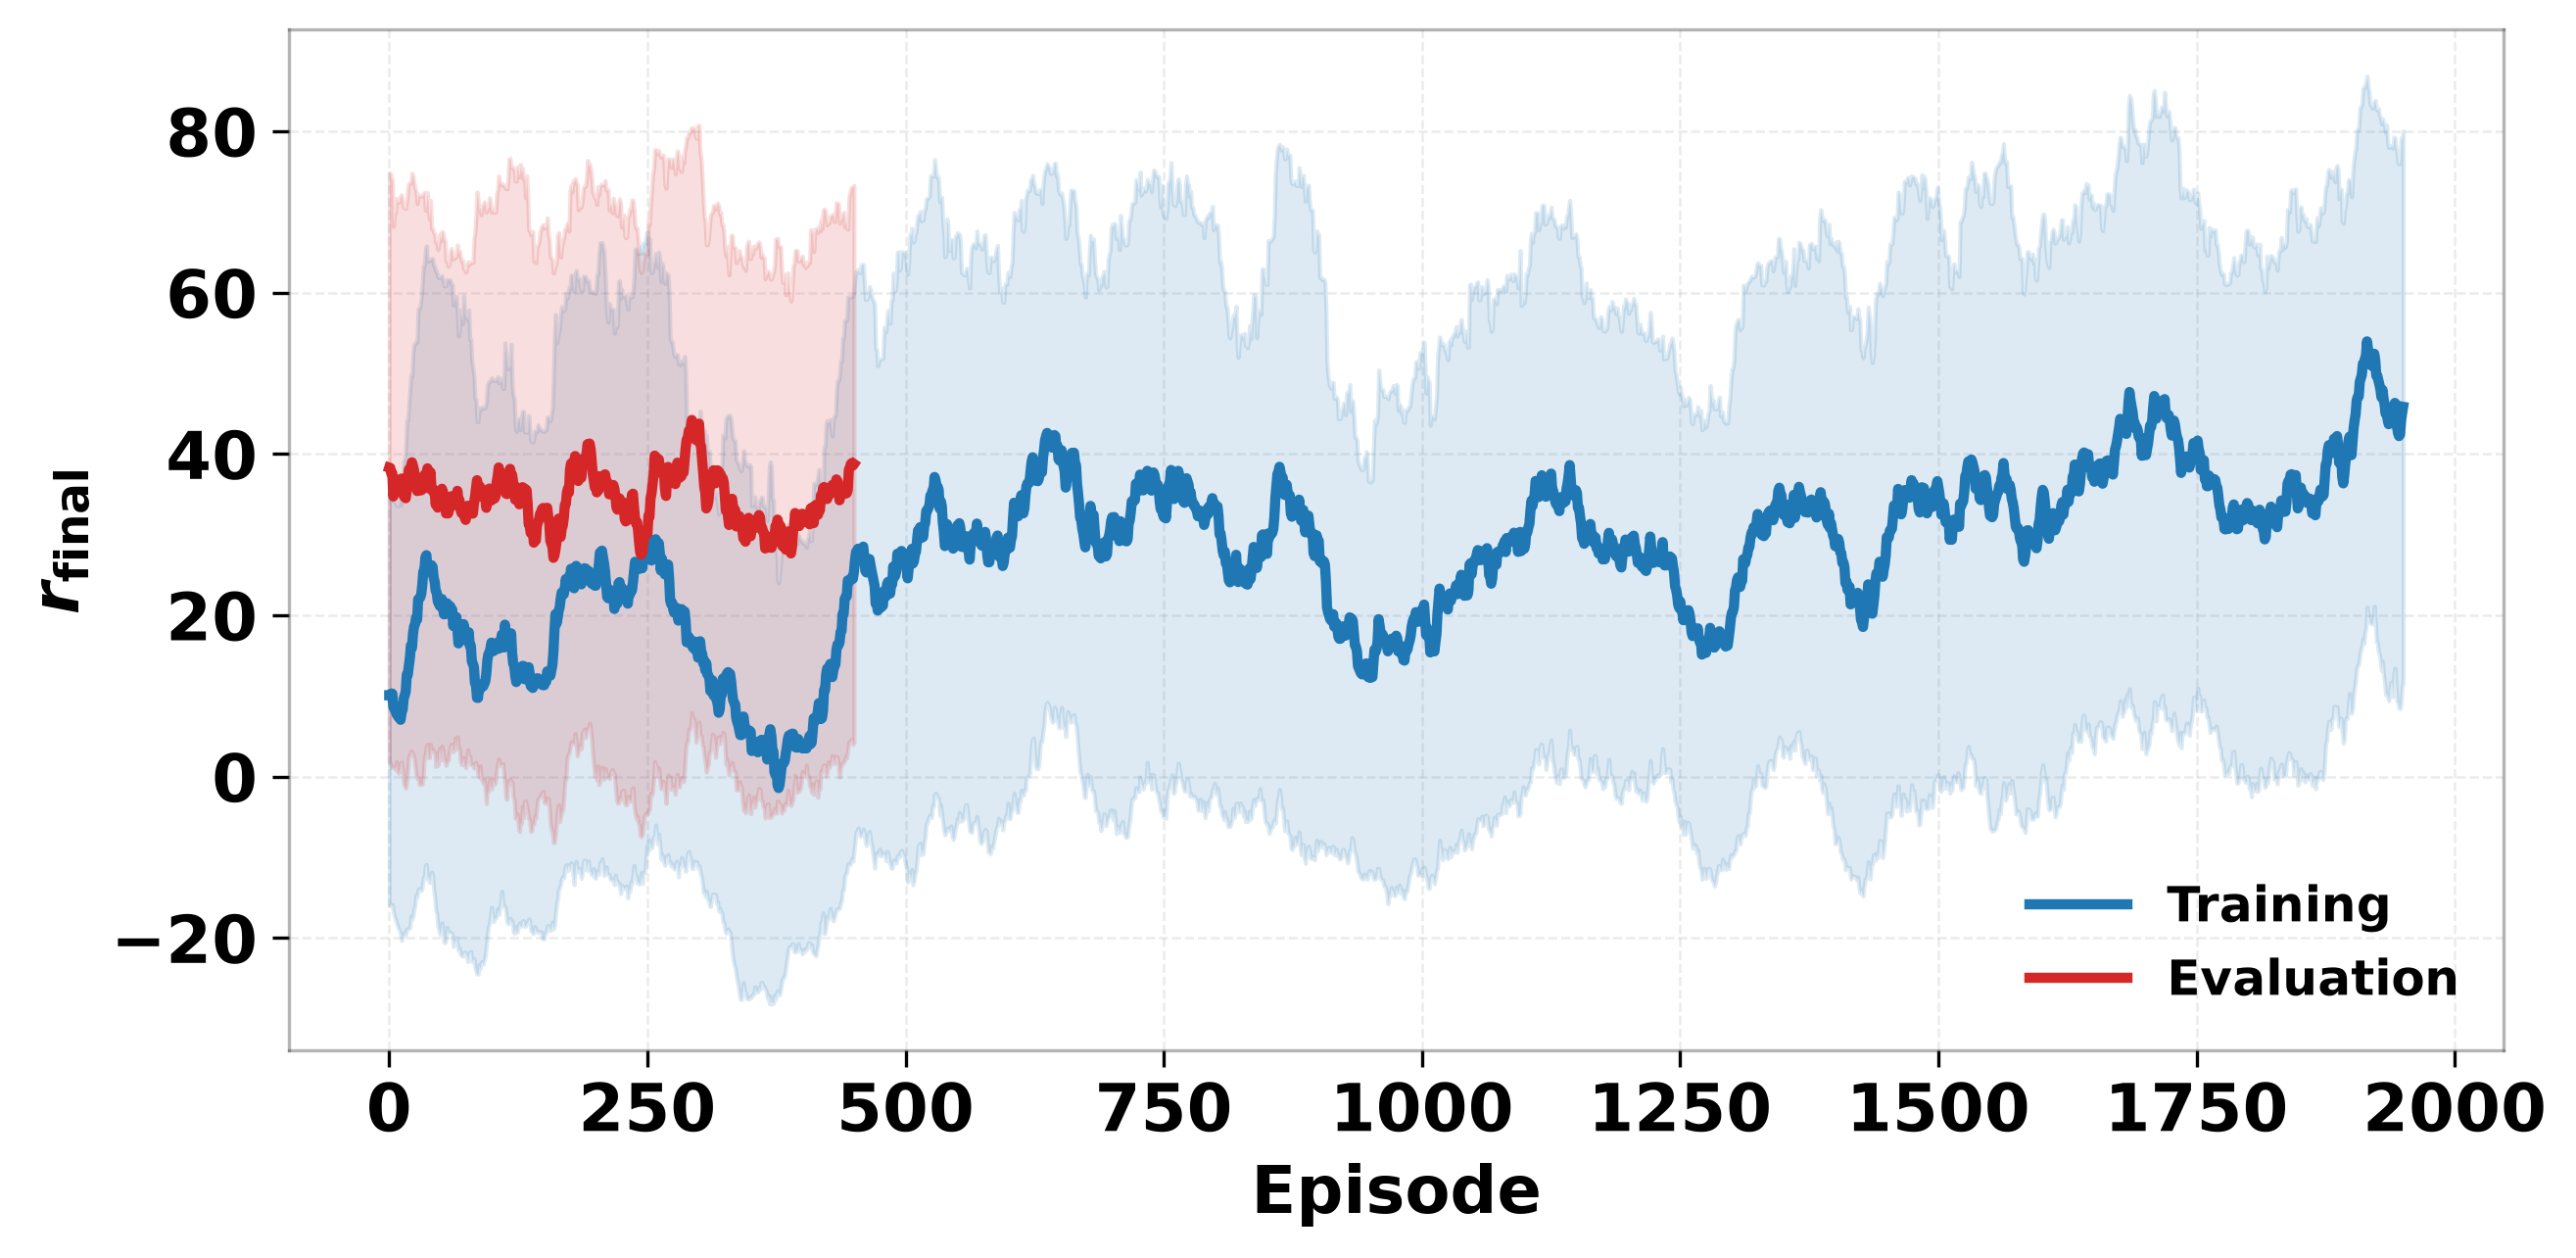

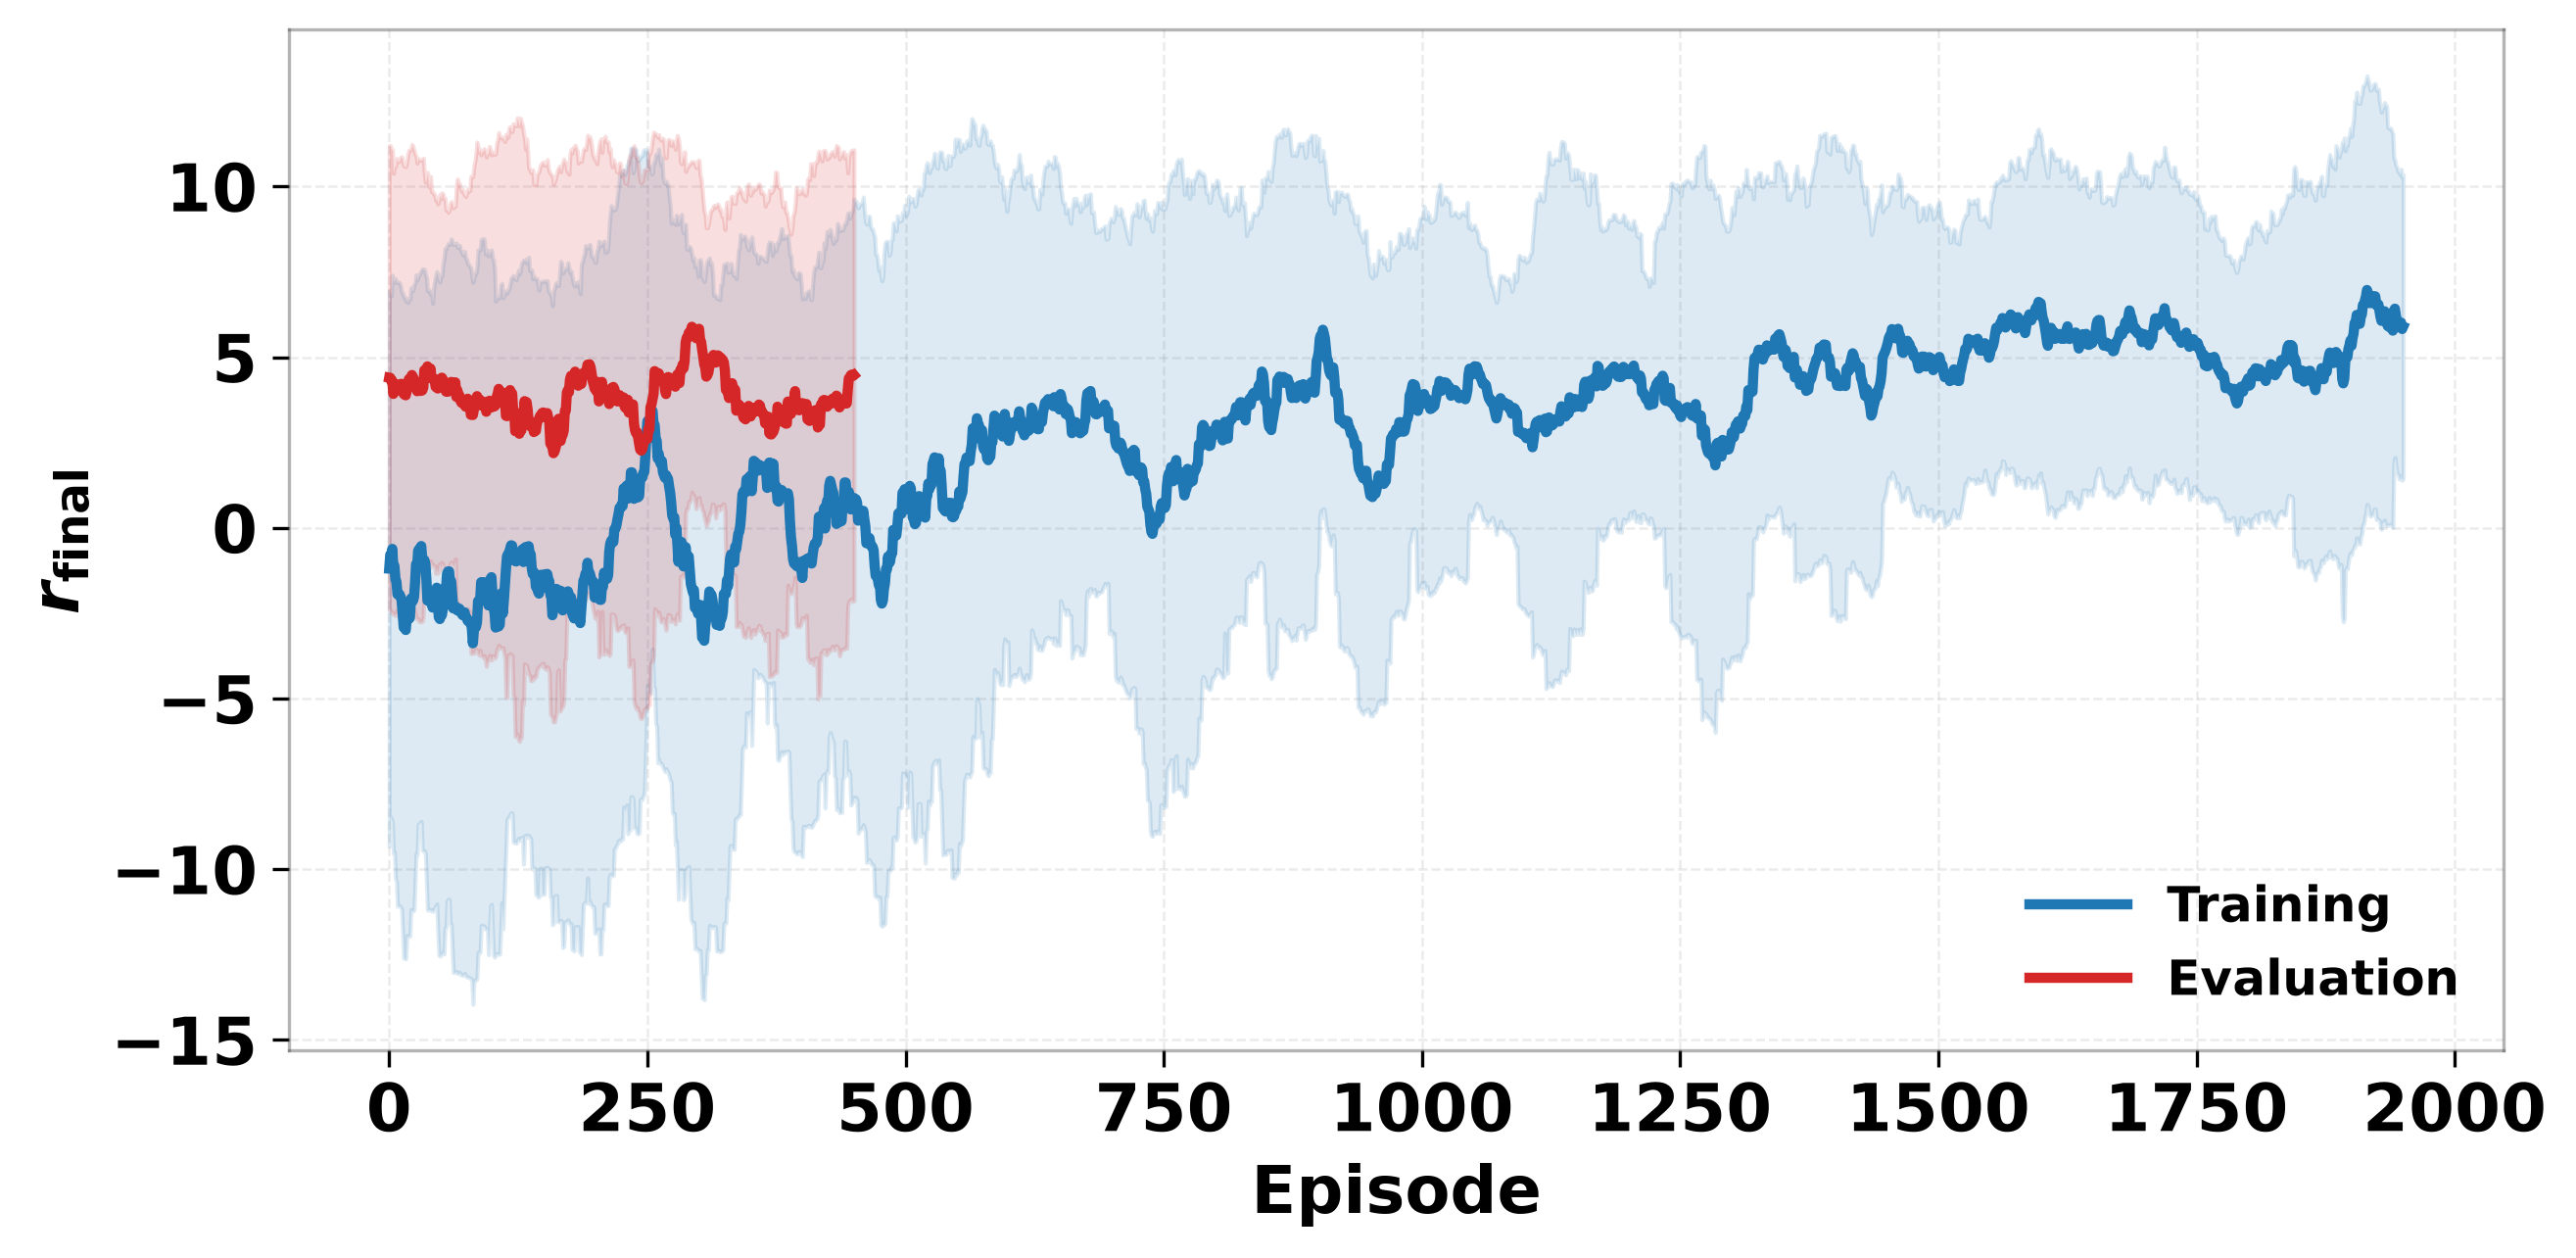

In [29]:
##Based on the originality without bias, classify the structures based on the bandgap
import numpy as np
import matplotlib.pyplot as plt
import random
import sys
sys.path.append("..")

from utils.utils import build_p4m_structure_simple, check_4_connectivity_single_component, get_fundamental_grid, strictly_enforce_4_connectivity

trained3cmsteel = np.load("DRLvib_revised_3cm_steel_trained/SAC3cm_trained_history.npy", allow_pickle=True)
eval3cmsteel_4cm = np.load("DRLvib_revised_3cm_steel_40_eval/eval_new_material_results.npy", allow_pickle=True)

trained4cmnylon= np.load("DRLvib_revised_4cm_with_PER/Updated_SAC_DISCRETE_PER_training_data_WO_frame_history.npy", allow_pickle=True)
trained4cmsteel= np.load("DRLvib_revised_4cm_Steel_train/SAC4cm_steel_train_with_history.npy", allow_pickle=True)
eval4cm_steel = np.load("DRLvib_revised_4cm_Steel_eval/eval_new_material_results.npy", allow_pickle=True) 

datasets = {
    "trained3cmsteel": trained3cmsteel,
    "eval3cmsteel_4cm": eval3cmsteel_4cm,
    "trained4cmnylon": trained4cmnylon,
    "trained4cmsteel": trained4cmsteel,
    "eval4cm_steel": eval4cm_steel}

def moving_average(x, w=50):
    return np.convolve(x, np.ones(w)/w, mode="valid")

def moving_std(x, w=50):
    return np.array([np.std(x[i:i+w]) for i in range(len(x)-w+1)])

plt.rcParams.update({"font.size": 14,"axes.titlesize": 15, "axes.labelsize": 15, "legend.fontsize": 12, "lines.linewidth": 2.5})
plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"

def extract_rewards(data):
    if "rewards" in data[0]:
        rewards = np.asarray([val["final_bandgap_reward"] for val in data])
        if rewards.ndim > 1:
            rewards = np.sum(rewards, axis=1)

    elif "final_reward" in data[0]:
        rewards = np.asarray([ val["final_reward"] for val in data])

    return rewards

def plot_comparison(train_data, eval_data, title):
    train_rewards = extract_rewards(train_data)
    eval_rewards = extract_rewards(eval_data)

    window = 50
    train_ma = moving_average(train_rewards, window)
    train_std = moving_std(train_rewards, window)

    eval_ma = moving_average(eval_rewards, window)
    eval_std = moving_std(eval_rewards, window)

    fig, ax = plt.subplots(figsize=(9, 4.5), dpi=300)
    ax.plot(np.arange(len(train_ma)),train_ma, color="#1f77b4", label="Training",linewidth=2.5)
    ax.fill_between(np.arange(len(train_ma)), train_ma - train_std, train_ma + train_std, color="#1f77b4", alpha=0.15)
    ax.plot(np.arange(len(eval_ma)), eval_ma, color="#d62728", label="Evaluation", linewidth=2.5)

    ax.fill_between(np.arange(len(eval_ma)), eval_ma - eval_std, eval_ma + eval_std, color="#d62728", alpha=0.15)

    ax.set_xlabel("Episode", fontsize=16, fontweight='bold')
    ax.set_ylabel(r"$r_{\mathrm{final}}$", fontsize=16, fontweight='bold')
    #ax.set_title(title)
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.25)

    ax.set_axisbelow(True)
    ax.legend(frameon=False)

    for spine in ax.spines.values():
        spine.set_linewidth(0.8)
        spine.set_color("#444444")
        spine.set_alpha(0.4)

    ax.tick_params(axis="both", which="major", labelsize=16, length=4, width=0.8)
    ax.tick_params(top=False, right=False)
    plt.tight_layout()
    plt.savefig(f"{title}.png", dpi=500, bbox_inches='tight')
    plt.show()

# Comparison 1: 4 cm steel
plot_comparison(trained4cmsteel, eval4cm_steel,"4_cm_Steel_Training_vs_Evaluation")
# Comparison 2: 3 cm steel training, 4 cm evaluation
plot_comparison(trained3cmsteel, eval3cmsteel_4cm, "3_cm_Steel_Training_vs_4cm_Steel_Evaluation")

#plt.savefig("Updated_SAC_DISCRETE_3cm_WO_history_reward_STEEL.png", dpi=500, bbox_inches='tight')
#plt.close()

In [ ]:
##this is for the case of evaluated

Mean reward: 2.7451
[1274 1212  102 1934  894  235 1464 1431  287 1018 1952  946 1371 1657
 1600 1391 1618  567 1871   52  528 1424  264 1926  679 1479 1353 1314
  313  272 1733 1702 1637 1171 1757 1510  872  612 1768 1643 1138  938
  825 1207  682 1328 1502 1687 1635]


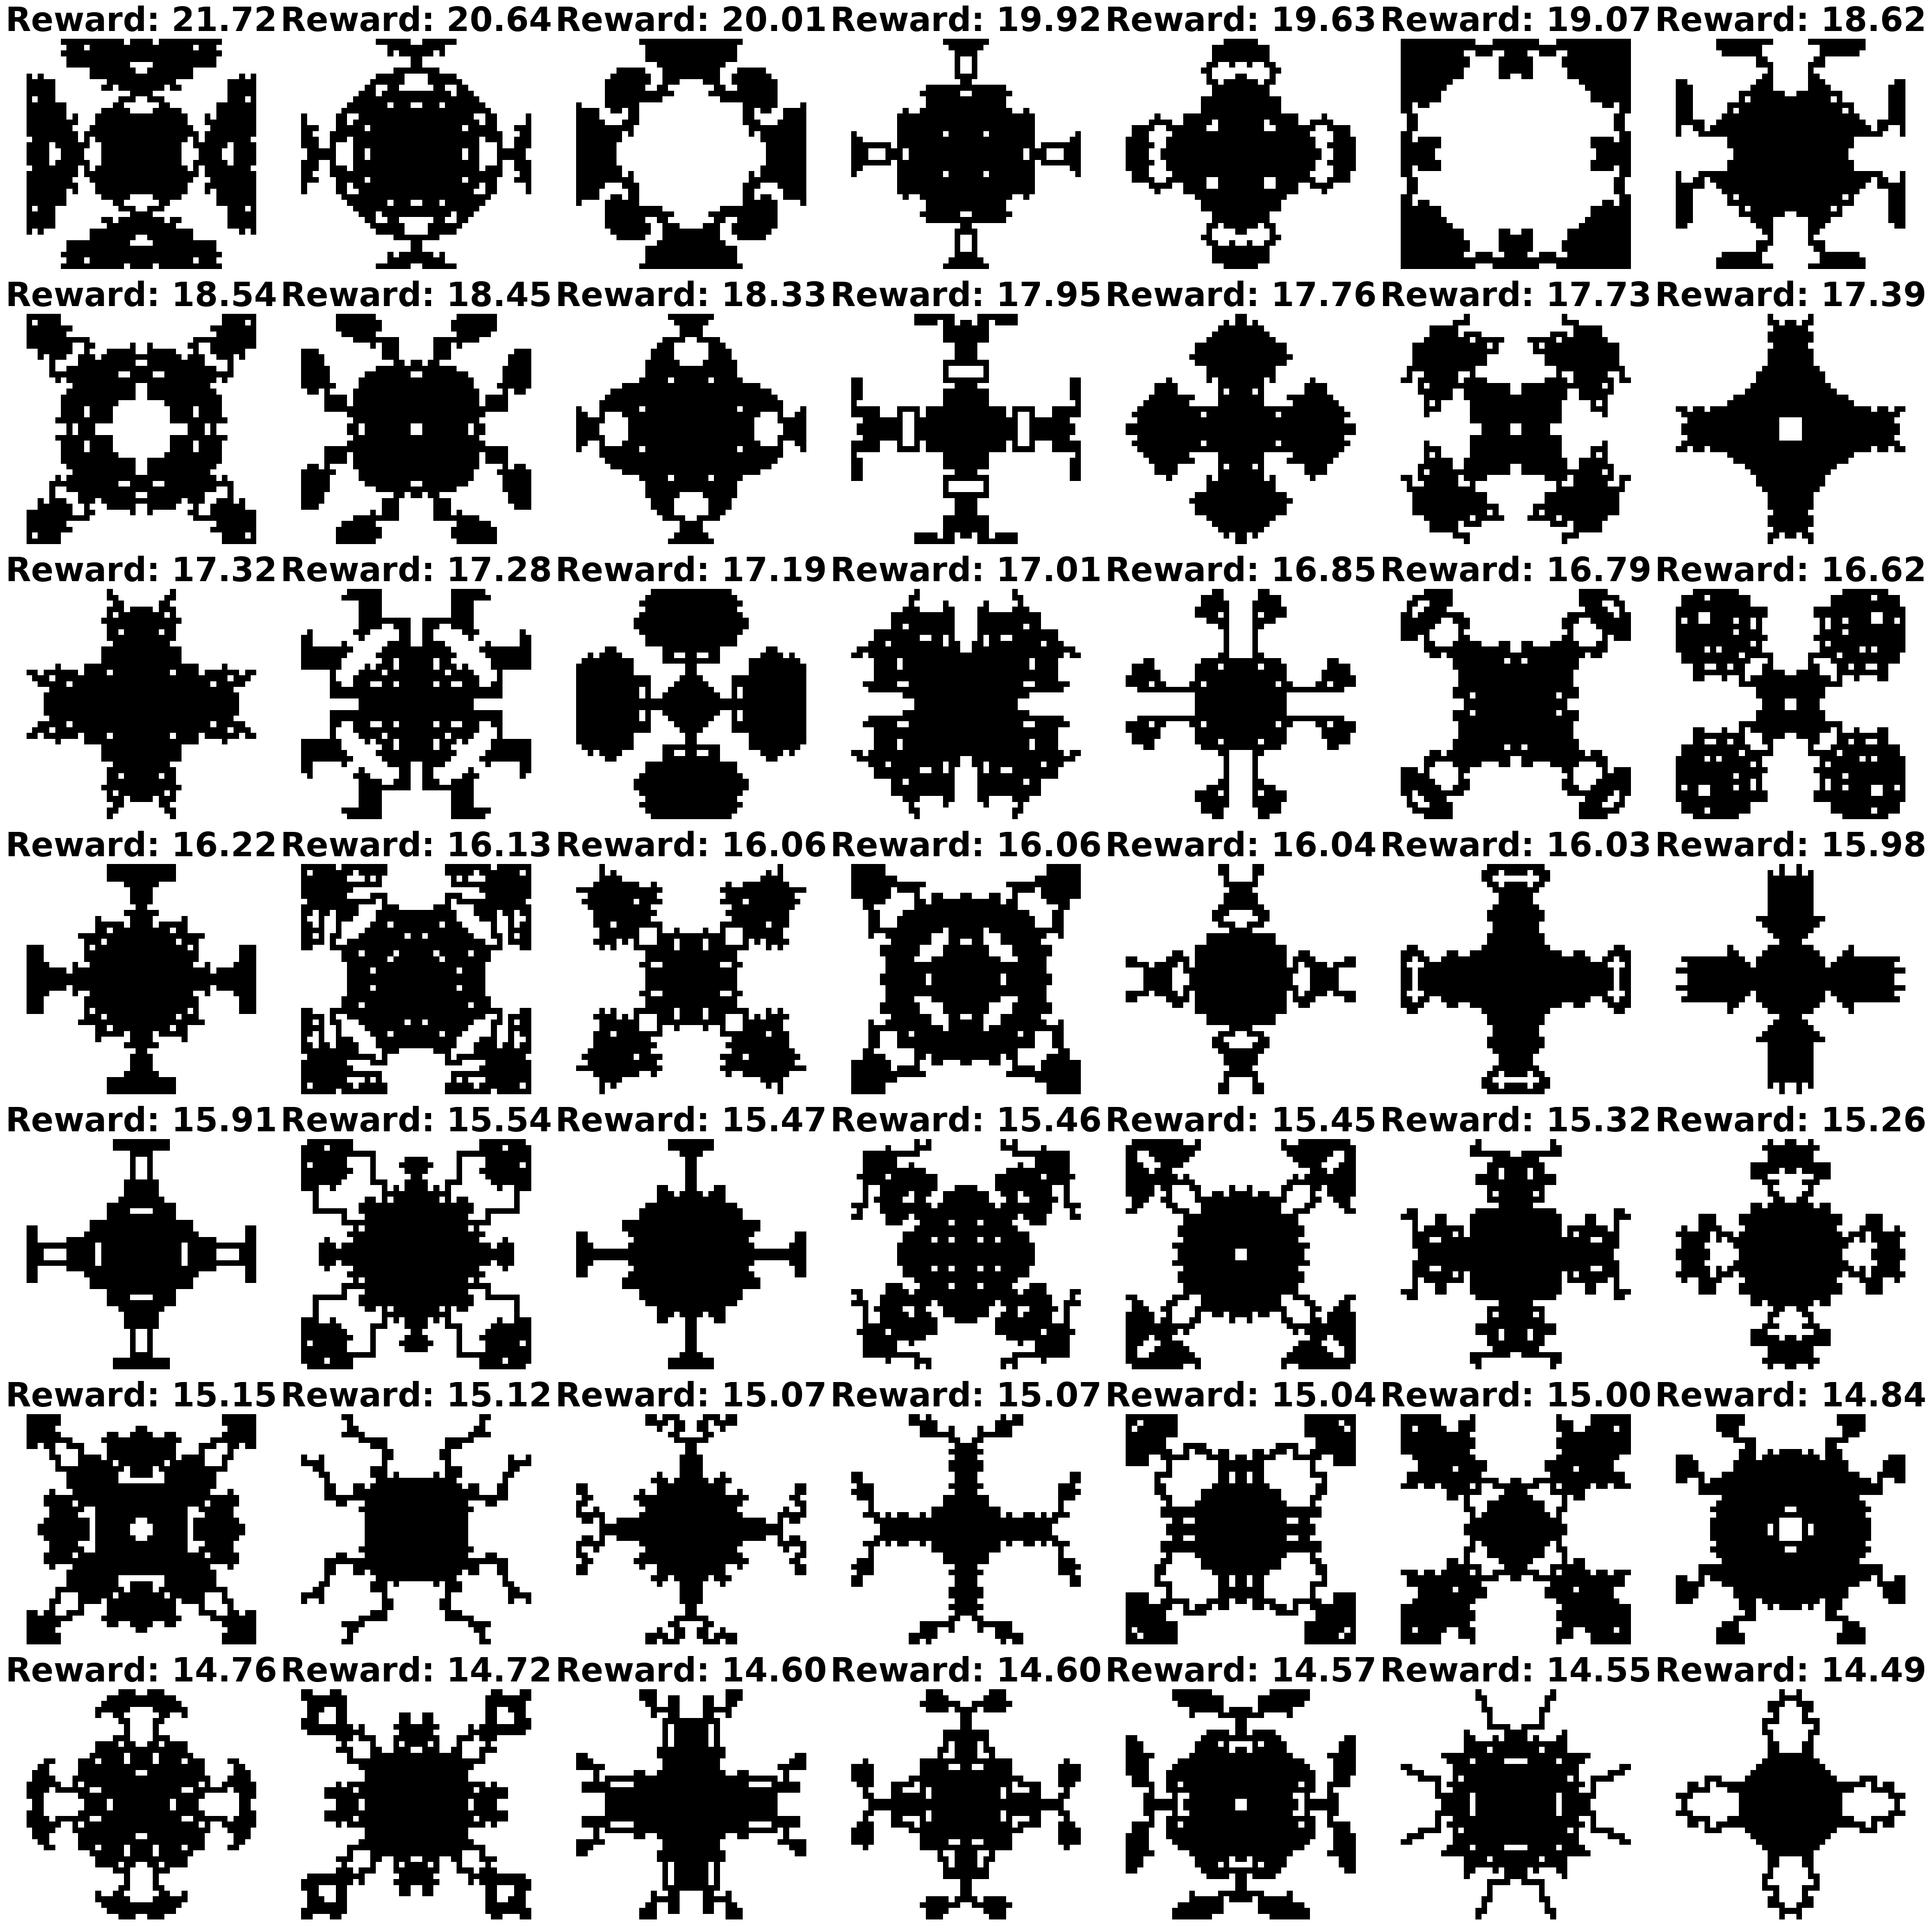

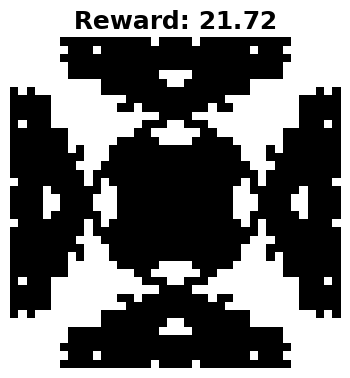

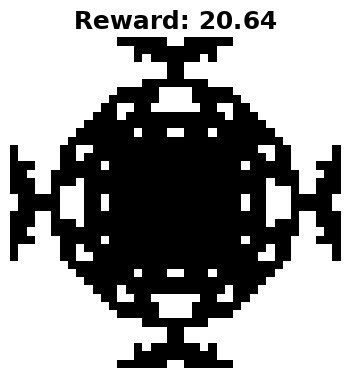

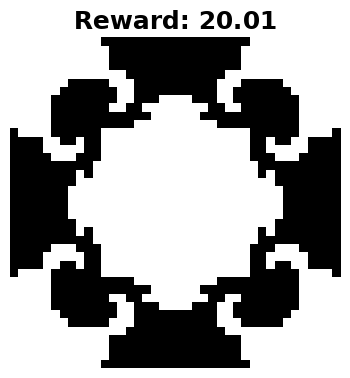

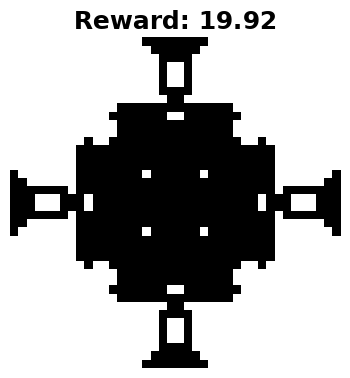

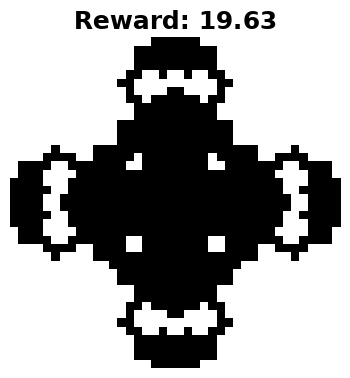

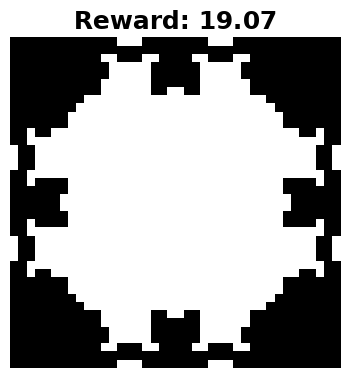

In [30]:

import numpy as np
import matplotlib.pyplot as plt
from utils.utils import check_4_connectivity_single_component

def select_high_reward_states(trained_data, n_samples=49, seed=2, train=True):
    if train:
        rewards = np.asarray([val['final_bandgap_reward'] for val in trained_data])
        states = [val['states'] for val in trained_data]
    else:
        rewards = np.asarray([val['final_reward'] for val in trained_data])
        states = [val['fund_grid'] for val in trained_data]

    #candidate_indices = np.where(rewards > np.mean(rewards))[0]
    selected_indices = np.argsort(rewards)[-n_samples:][::-1]

    print(f"Mean reward: {np.mean(rewards):.4f}")
    return rewards, states, selected_indices

def reconstruct_structure(state, train=True):
    if train:
        path = np.unique(np.asarray(state, dtype=int), axis=0)
        grid = get_fundamental_grid(20, path)
        grid = strictly_enforce_4_connectivity(build_p4m_structure_simple(grid))
        is_connected, _ = check_4_connectivity_single_component(grid)
    else:
        grid = np.asarray(state).reshape(20, 20)
        grid = strictly_enforce_4_connectivity(build_p4m_structure_simple(grid))
        is_connected, _ = check_4_connectivity_single_component(grid)
        
    return grid, is_connected


def plot_high_reward_structures(states, rewards, selected_indices, title, train=True):
    fig, axes = plt.subplots(7, 7, figsize=(35, 35))
    axes = axes.flatten()
    valid_indices = []
    for ax, idx in zip(axes, selected_indices):
        grid, is_connected = reconstruct_structure(states[idx], train)
        if is_connected:
            ax.imshow(grid, cmap="gray", origin="lower")
            ax.set_title(f"Reward: {rewards[idx]:.2f}", fontsize=43, fontweight='bold')
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(f"{title}.png", dpi=500, bbox_inches='tight')
    plt.show()
    return valid_indices

#plot one structure at a time for the first six high reward states
def plot_targeted_structures(states, rewards, selected_indices, title, train=True):
    fig, ax = plt.subplots(figsize=(4, 4))
    #axes = axes.flatten()
    valid_indices = []
    for idx in selected_indices:
        grid, is_connected = reconstruct_structure(states[idx], train)
        if is_connected:
            ax.imshow(grid, cmap="gray", origin="lower")
            ax.set_title(f"Reward: {rewards[idx]:.2f}", fontsize=18, fontweight='bold')
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(f"{title}.png", dpi=500, bbox_inches='tight')
    plt.show()
    return valid_indices
    
reward_train, states, rx_train = select_high_reward_states(trained3cmsteel)
print(rx_train)
valid_indices = plot_high_reward_structures(states, reward_train, rx_train, "trained3cm_steel")
for i in rx_train[:6]:
    vind = plot_targeted_structures(states, reward_train, [i], f"trained3cm_steel_{i}")

[1274 1212  102 1934  894  235]


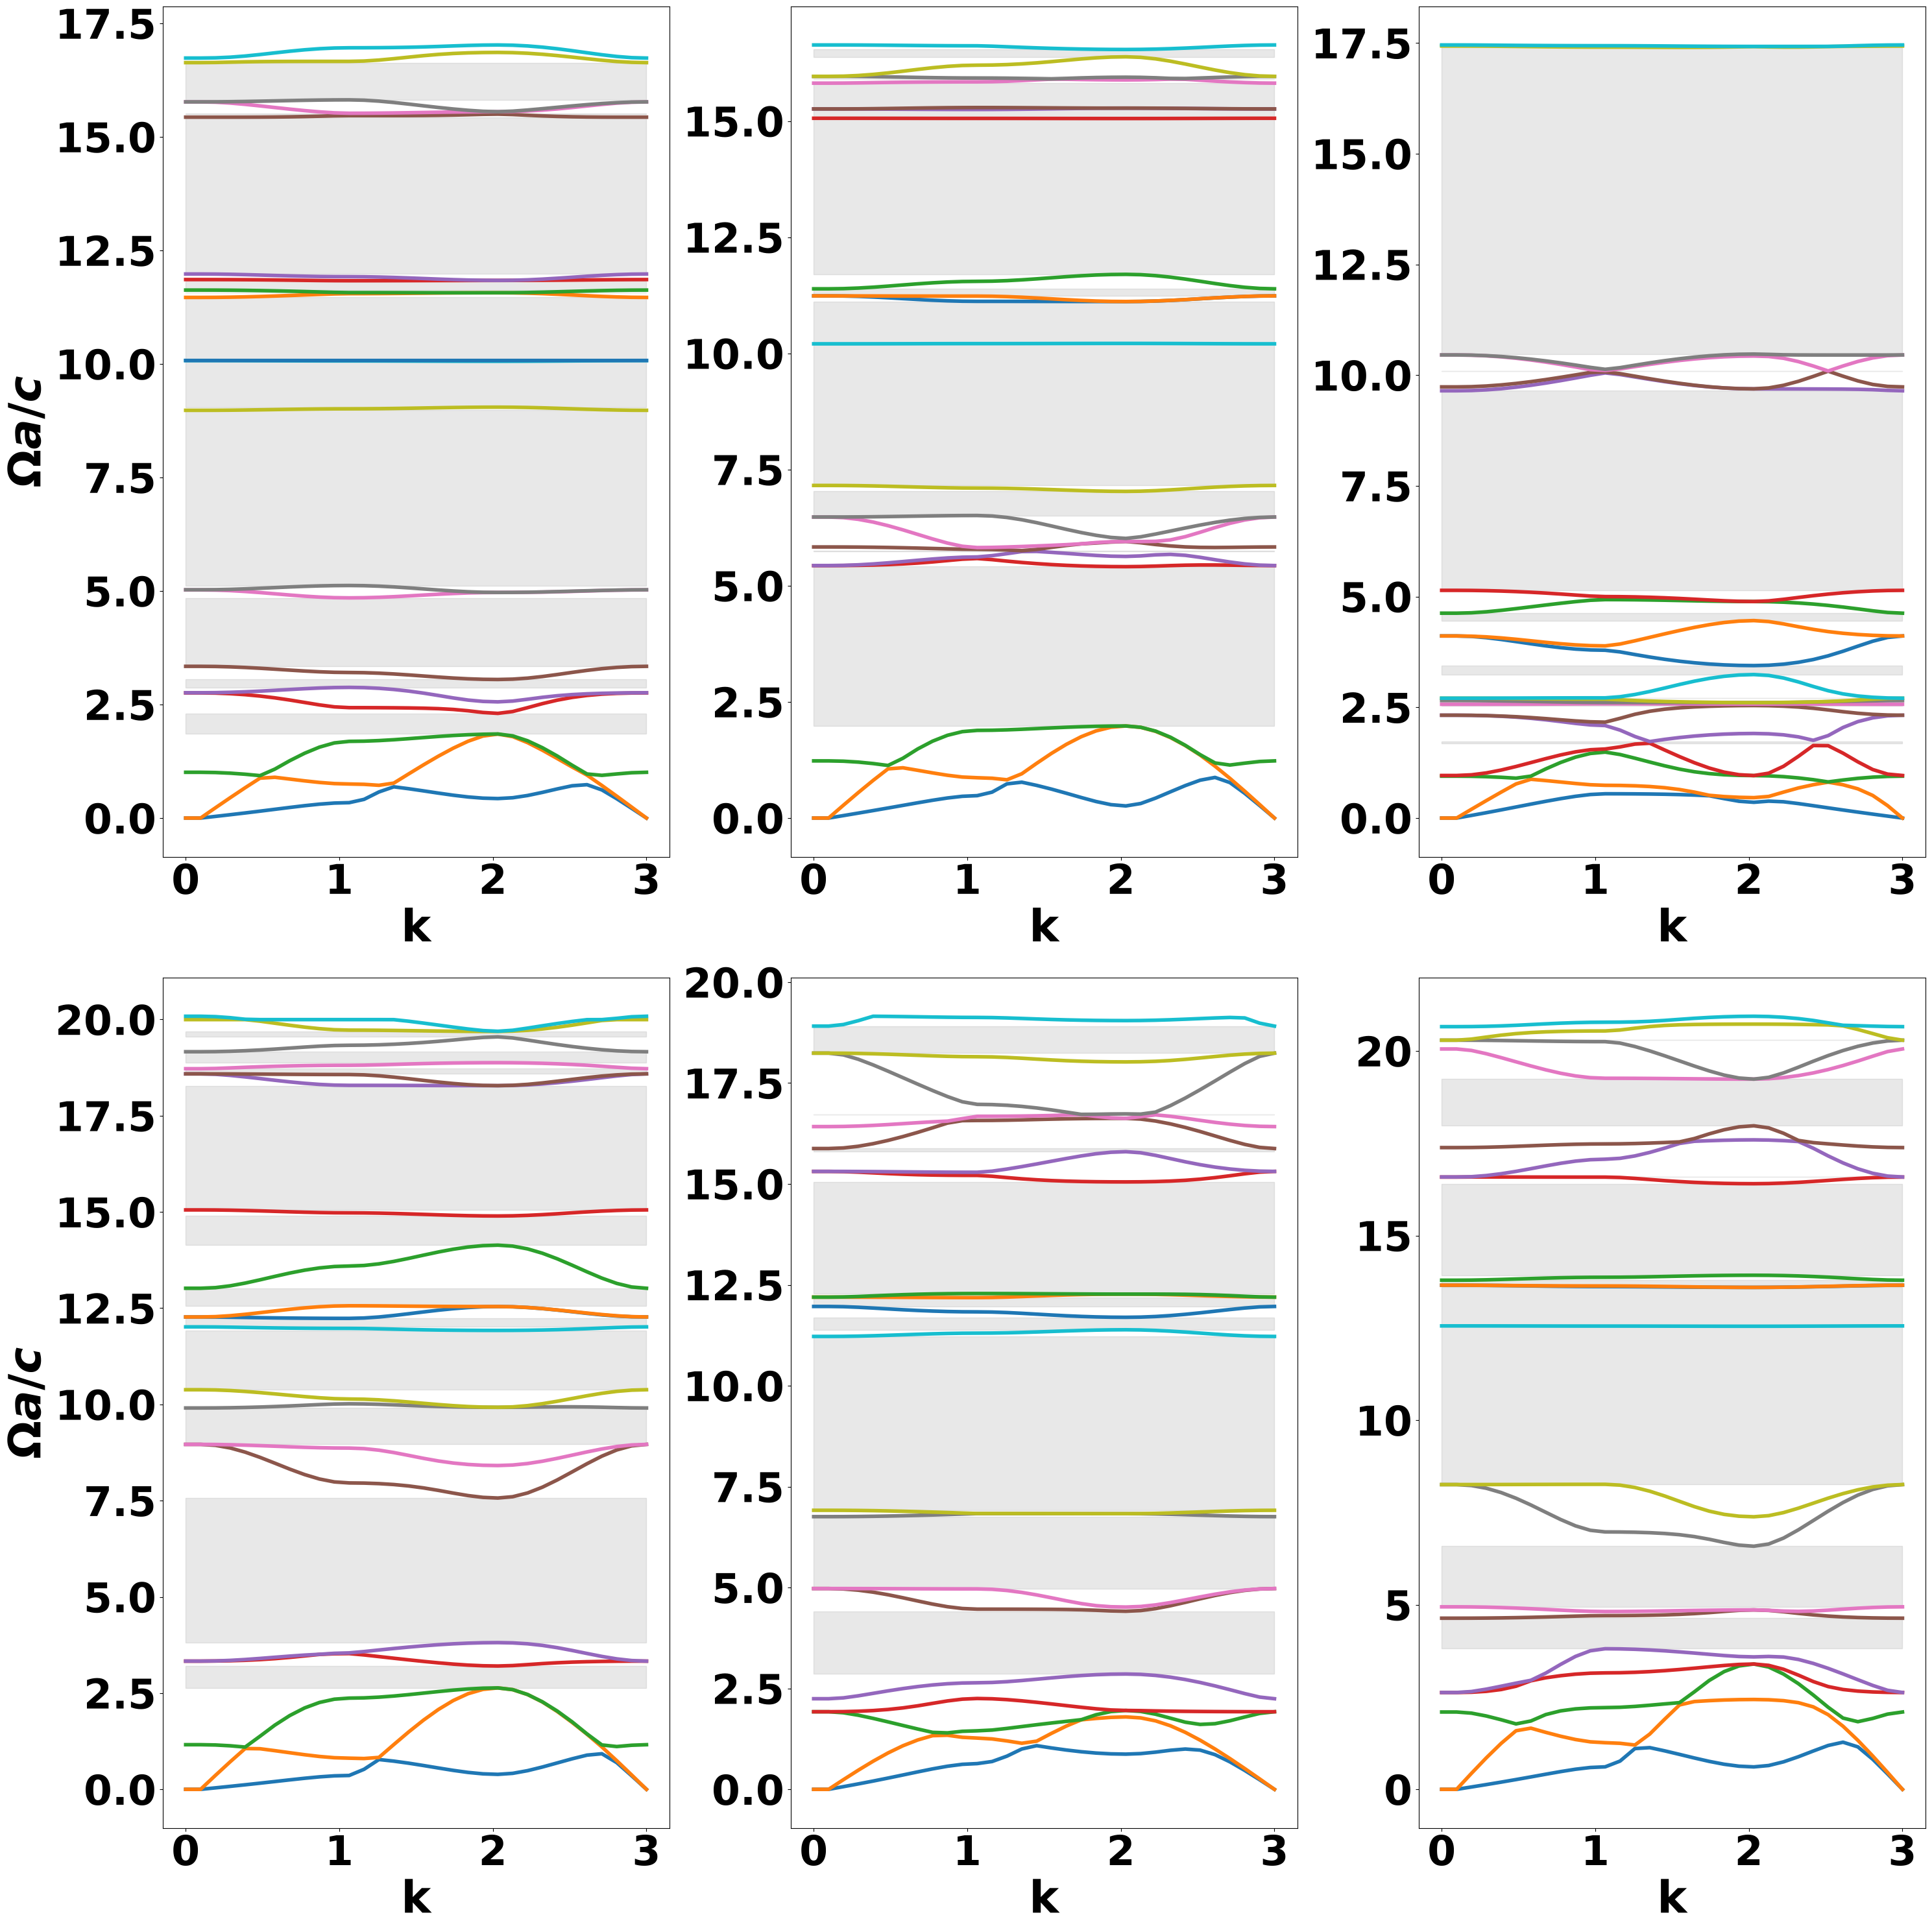

In [44]:
def plot_selected_bandstructures(trained_data, selected_indices, cell_size, title):
    bandgaps = [np.asarray(val['bandgap']) for val in trained_data]
    k = np.linspace(0, 3, 32)
    plt.rcParams.update({"font.size": 14, "axes.titlesize": 14, "axes.labelsize": 14, "legend.fontsize": 14, "lines.linewidth": 2})
    fig, axes = plt.subplots(2, 3, figsize=(30, 30))
    axes = axes.flatten()
    for i, (ax, idx) in enumerate(zip(axes, selected_indices)):
        data_sorted = np.sort(bandgaps[idx] * cell_size / 343, axis=1)
        ax.plot(k, data_sorted, linewidth=4)
        for b in range(data_sorted.shape[1] - 1):
            lower, upper = data_sorted[:, b], data_sorted[:, b + 1]
            gap_lower, gap_upper = np.max(lower), np.min(upper)
            if gap_upper > gap_lower:
                ax.fill_between(k, gap_lower, gap_upper, color="gray", alpha=0.18)
        ax.set_xlabel("k", fontsize=50)
        ax.set_ylabel(r"$\Omega a/c$" if i % 3 == 0 else "", fontsize=50)
        ax.tick_params(axis="both", labelsize=45)
        #ax.set_title(f"Structure {idx}", fontsize=25)
    plt.tight_layout()
    plt.savefig(f"{title}.png", dpi=500, bbox_inches='tight')
    plt.show()
    return selected_indices
sel_ind = rx_train[:6]
cell3cm = 0.03
print(sel_ind)
selected_indices = plot_selected_bandstructures(trained3cmsteel, sel_ind, cell3cm, "trained3cmsteel_bandgap")

Mean reward: 3.9453


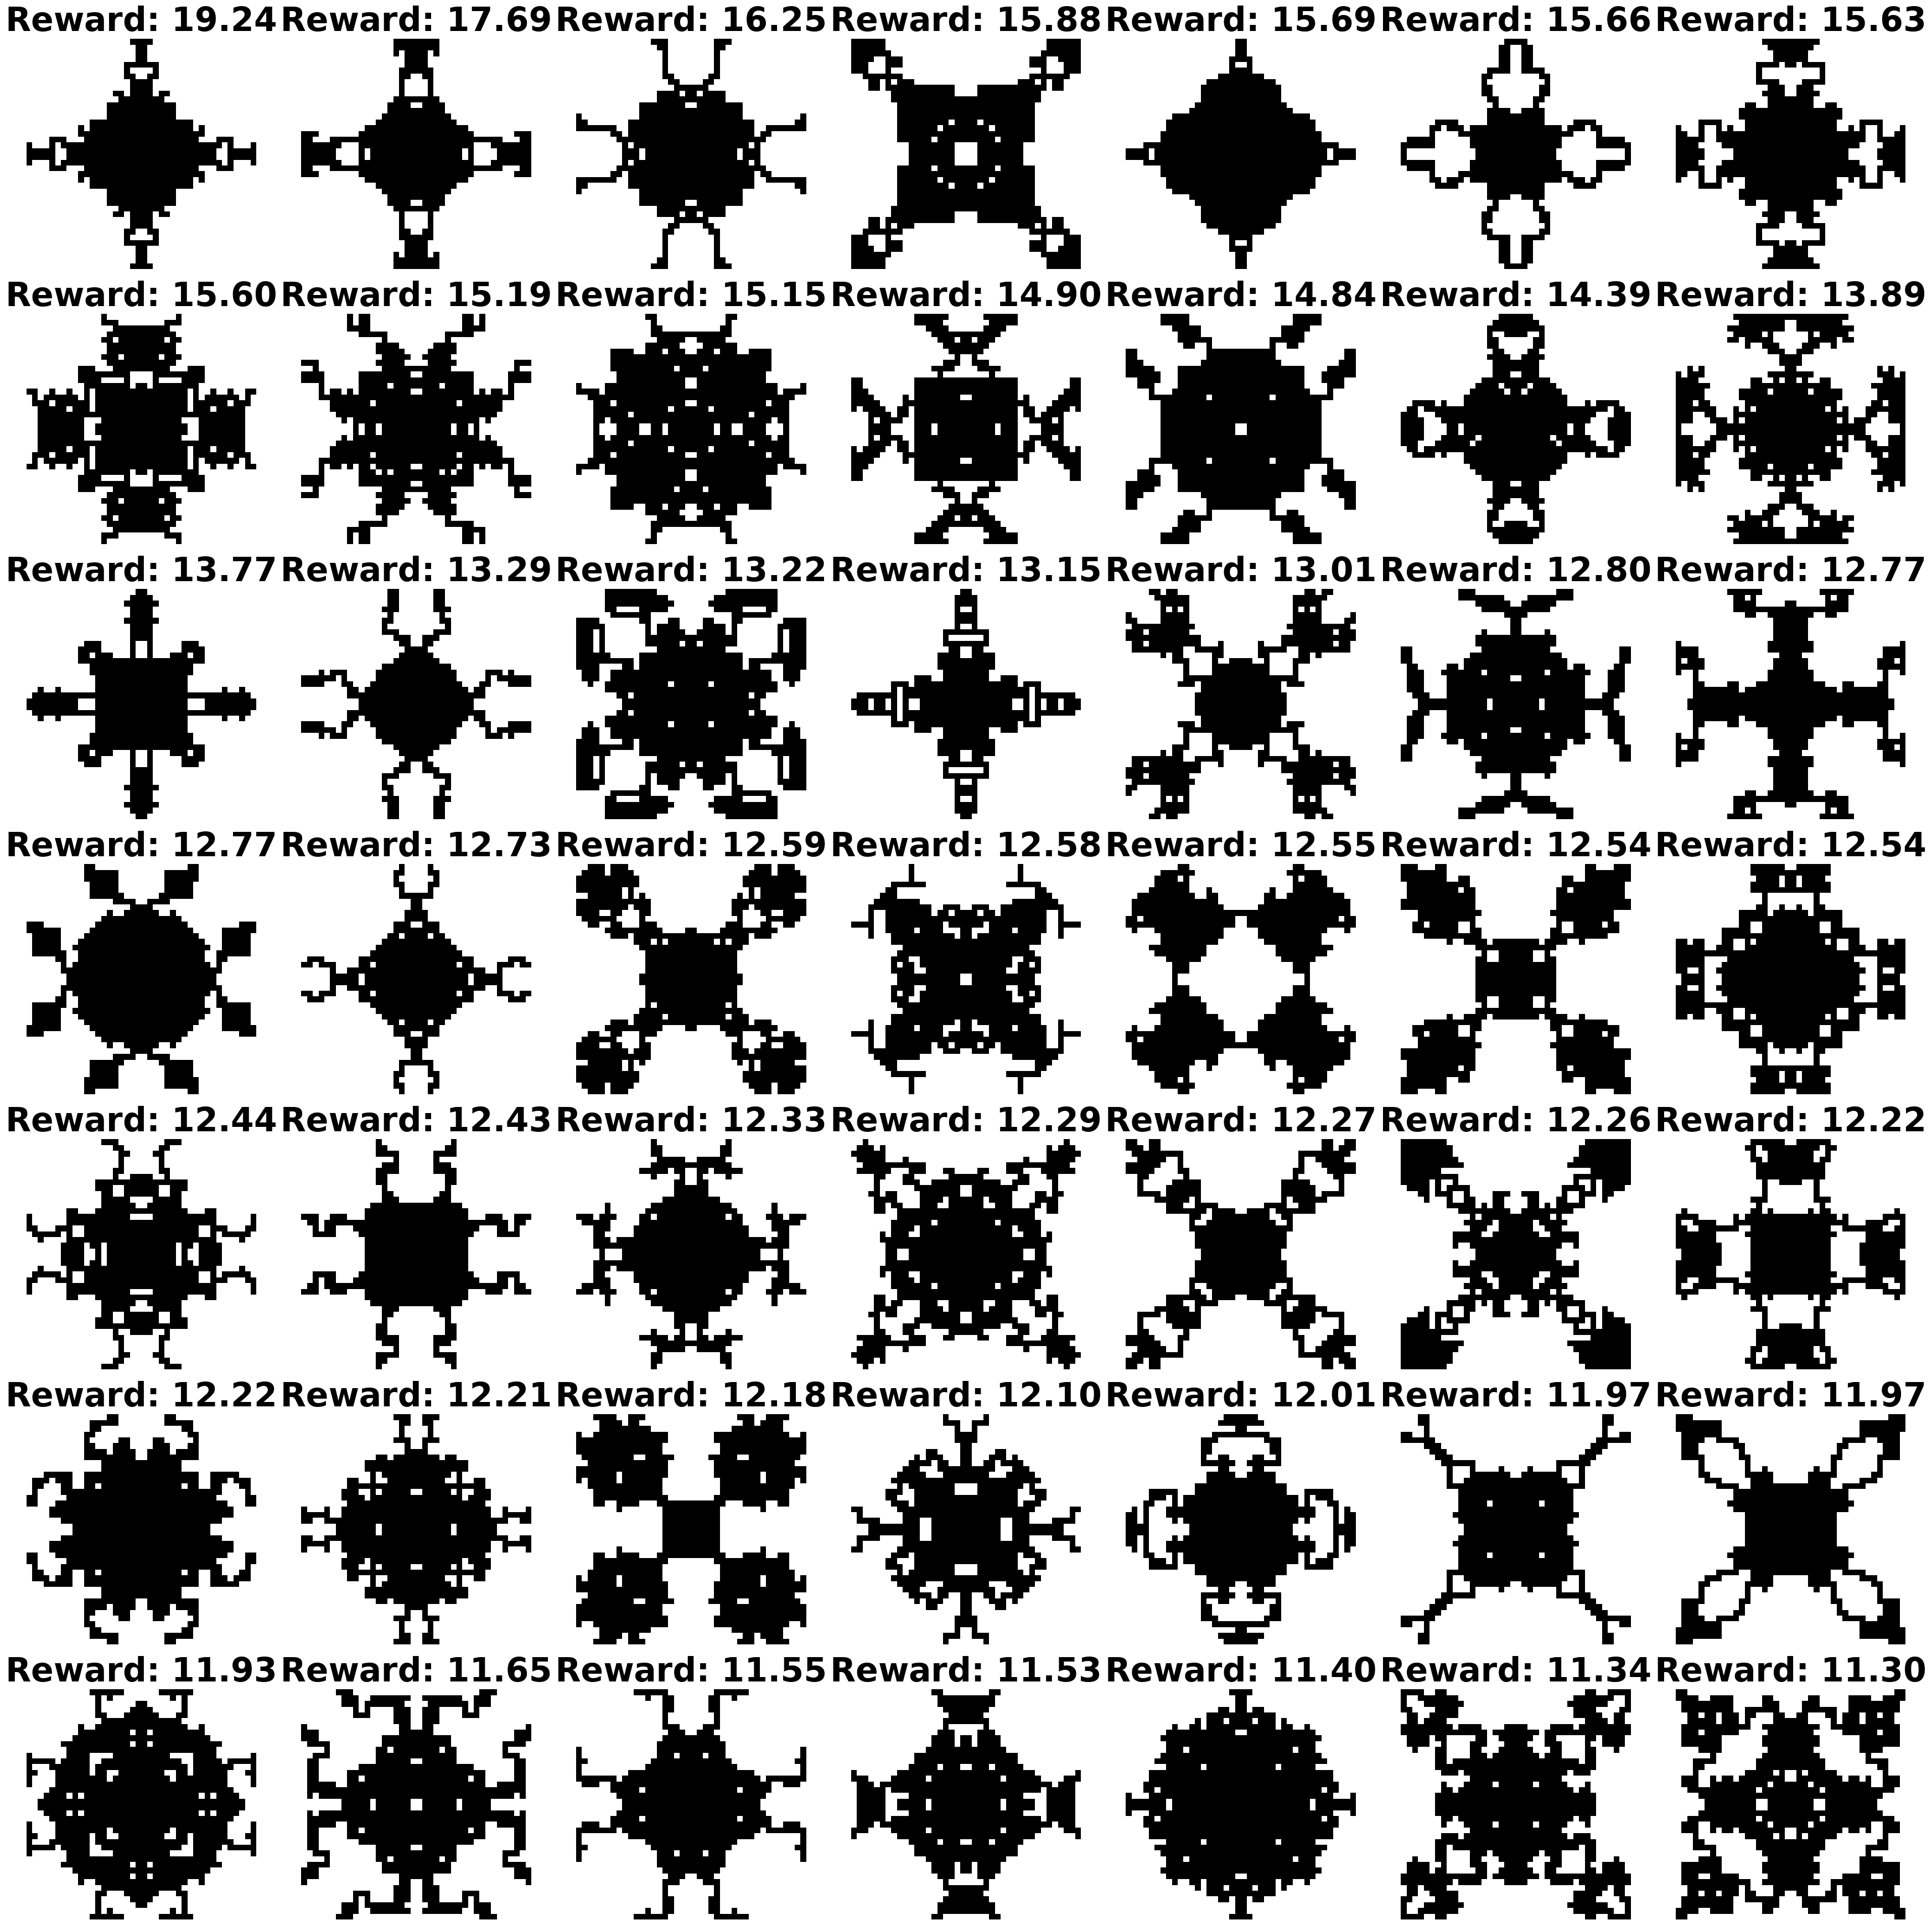

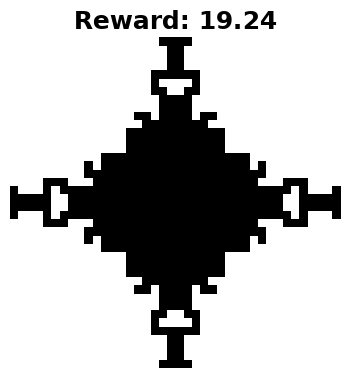

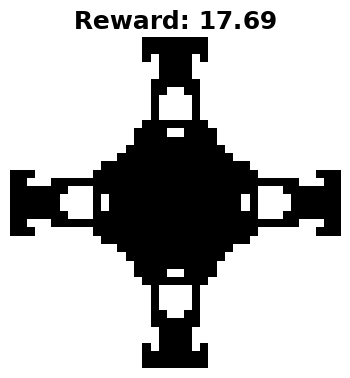

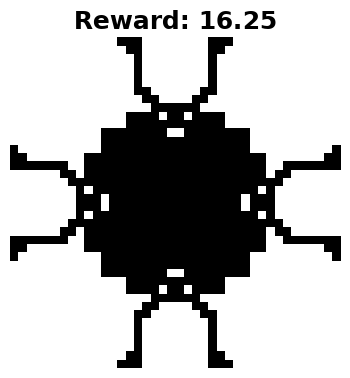

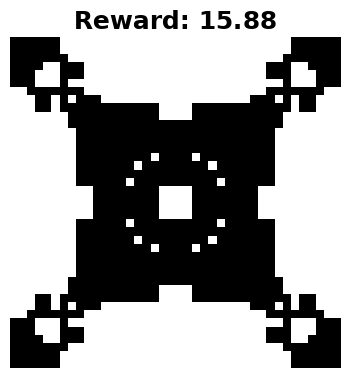

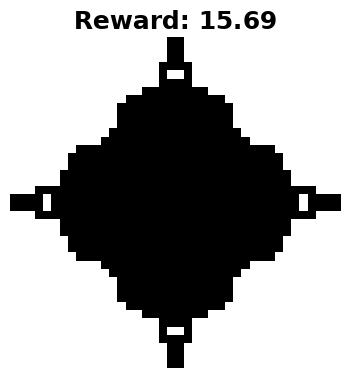

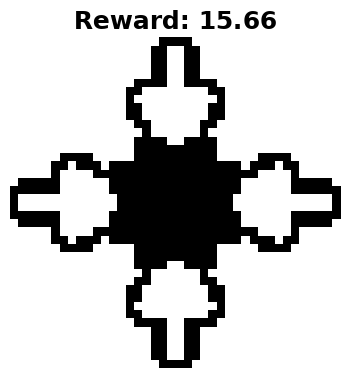

In [46]:
reward_test, states_test, rx_test = select_high_reward_states(eval3cmsteel_4cm, train=False)
valid_indices_test = plot_high_reward_structures(states_test, reward_test, rx_test, "eval3cmsteel_4cm_states", train=False)

for i in rx_test[:6]:
    vind = plot_targeted_structures(states_test, reward_test, [i], f"eval3cmsteel_4cm_{i}", train=False)

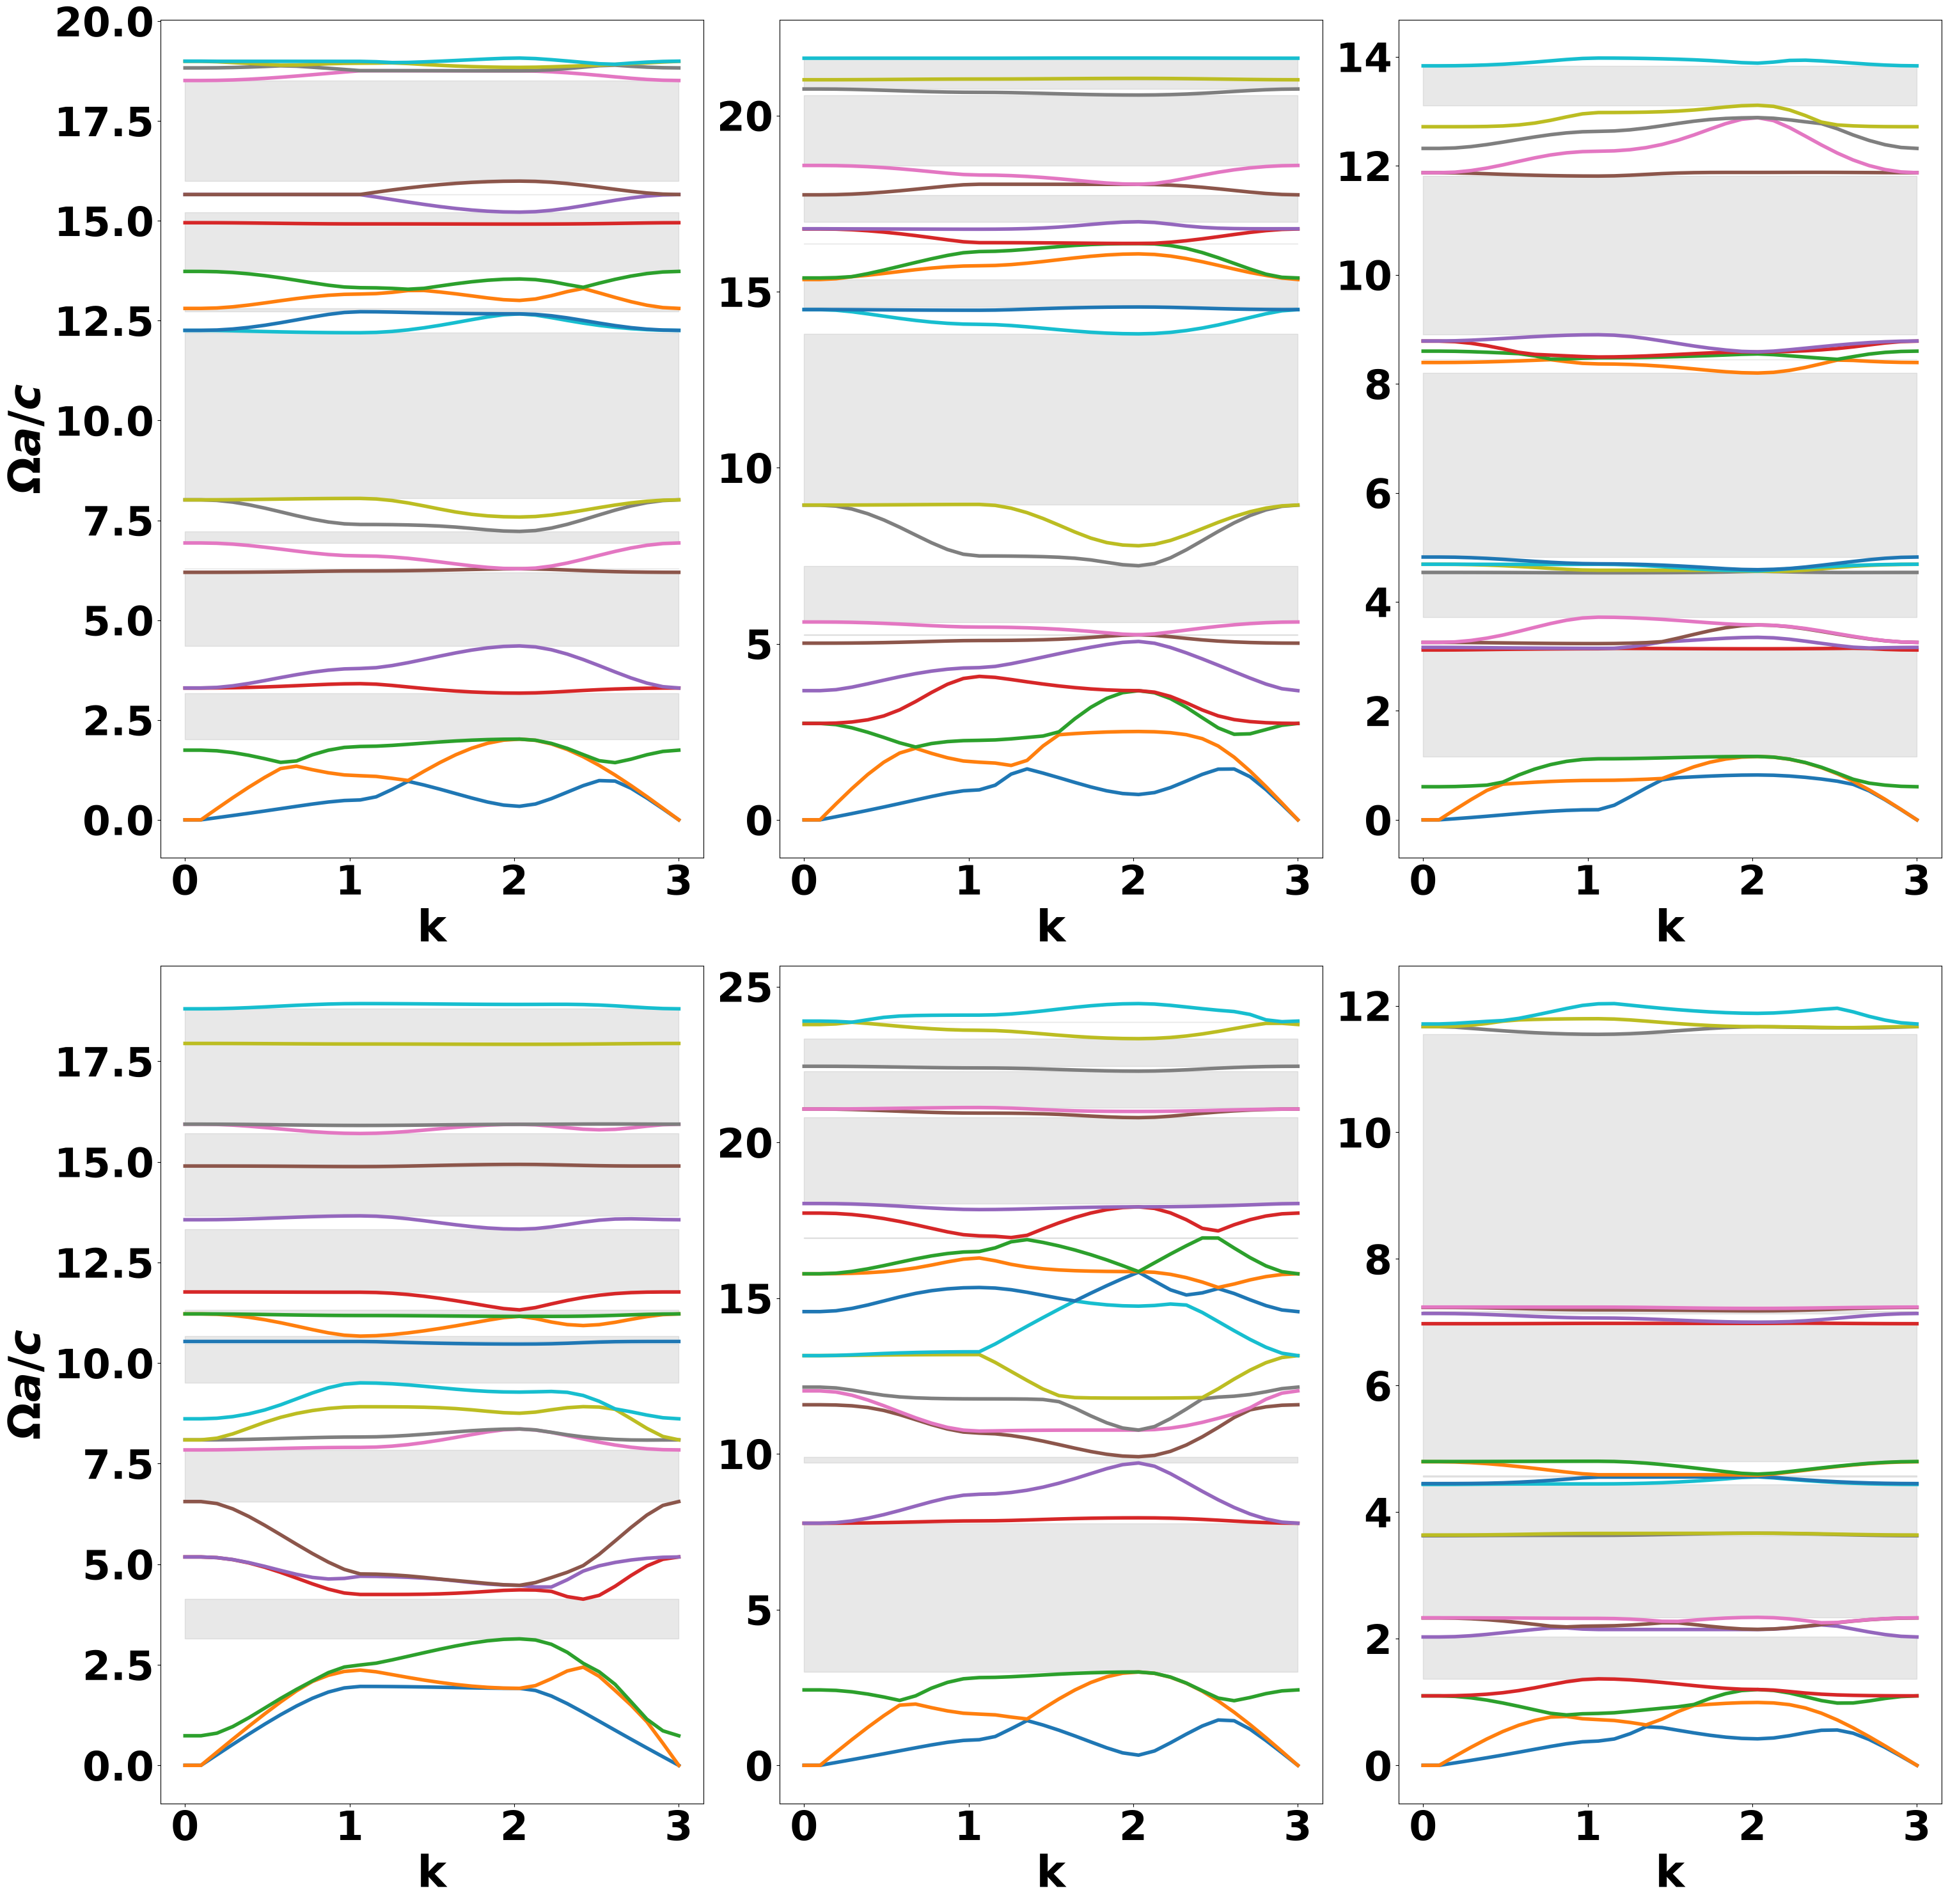

In [47]:
sel_ind_test = rx_test[:6]
selected_indices = plot_selected_bandstructures(eval3cmsteel_4cm, sel_ind_test, cell3cm, "eval3cmsteel_4cm_bandgaps")

Mean reward: 27.5686


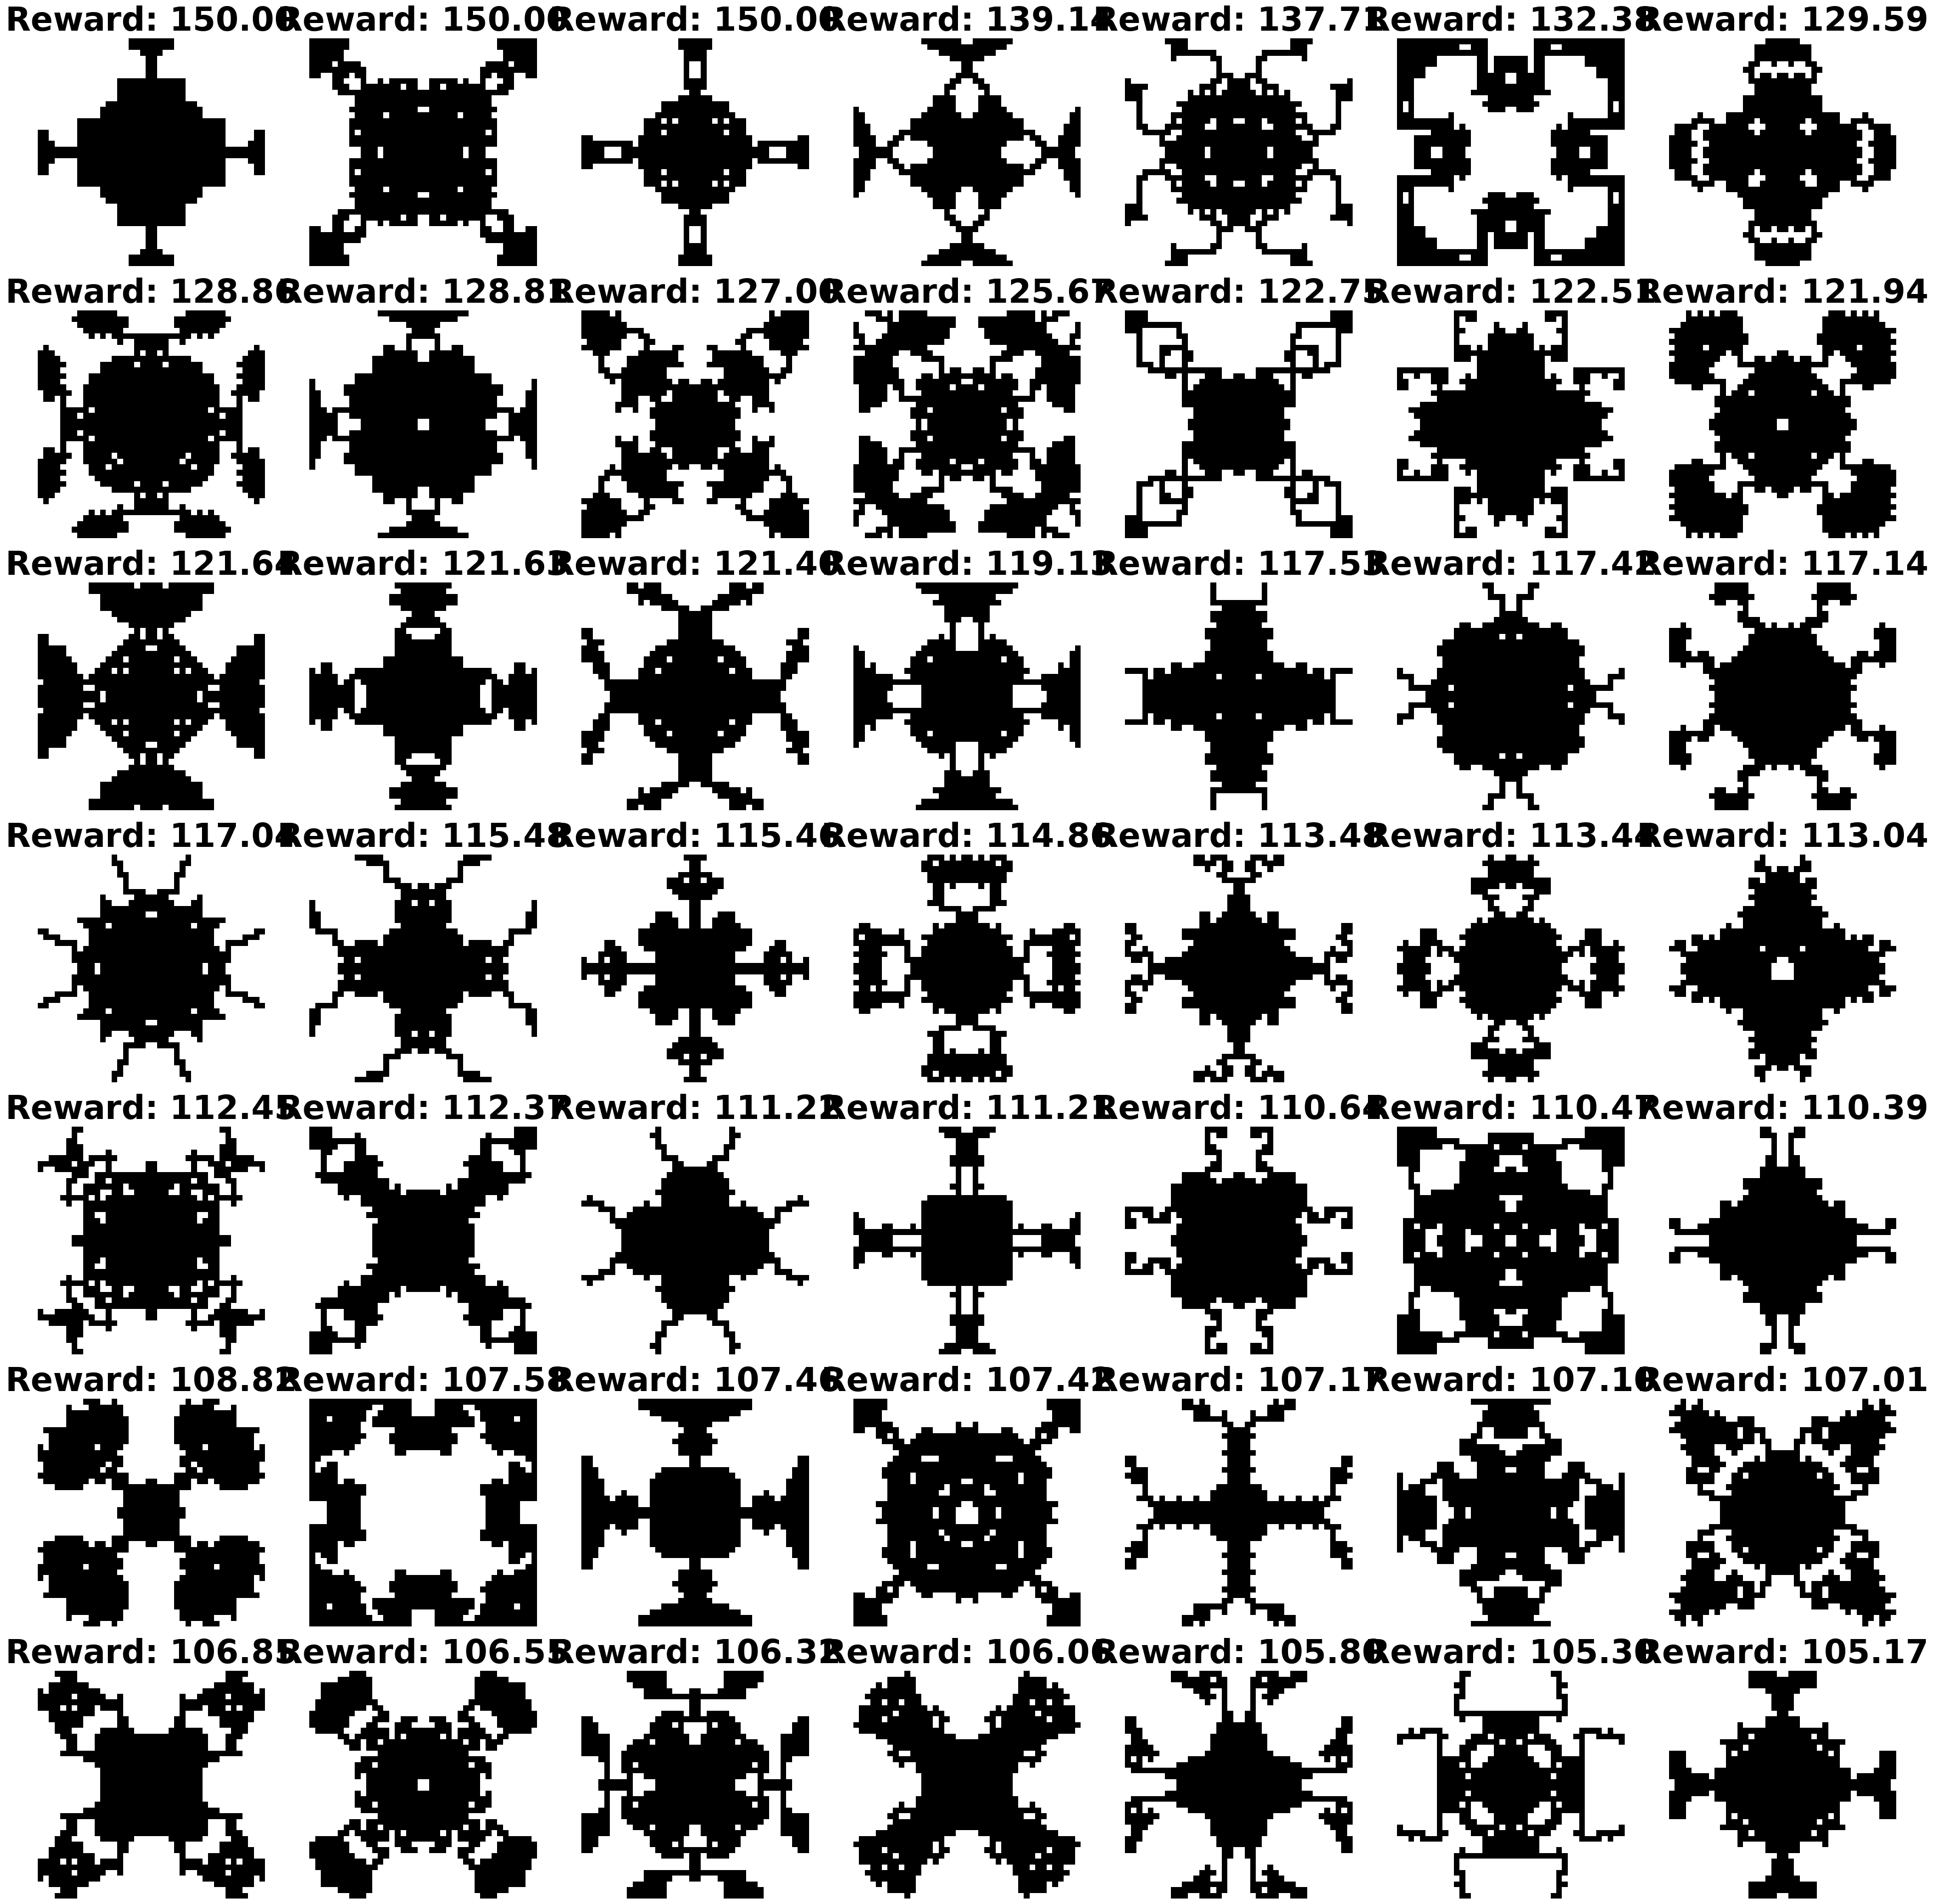

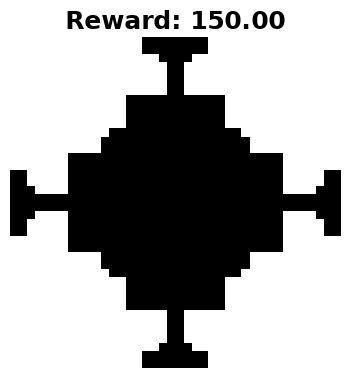

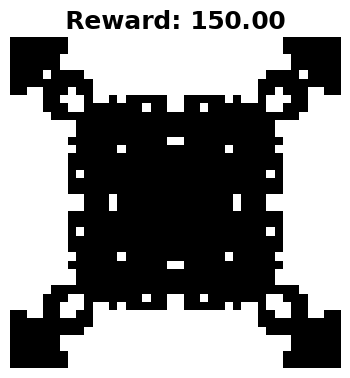

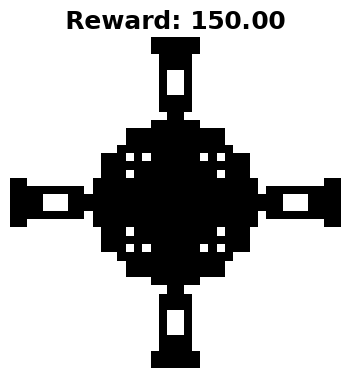

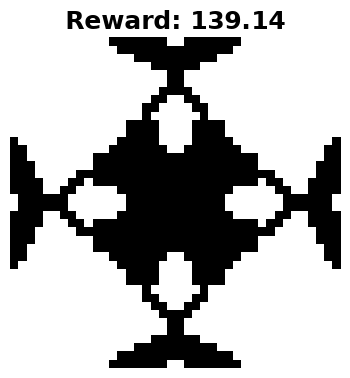

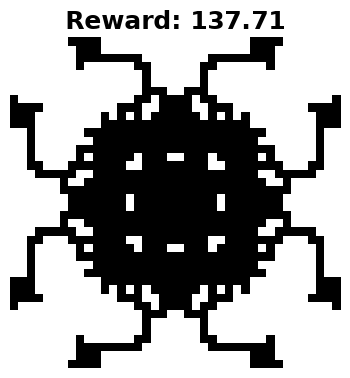

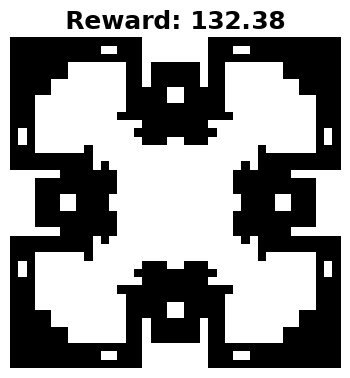

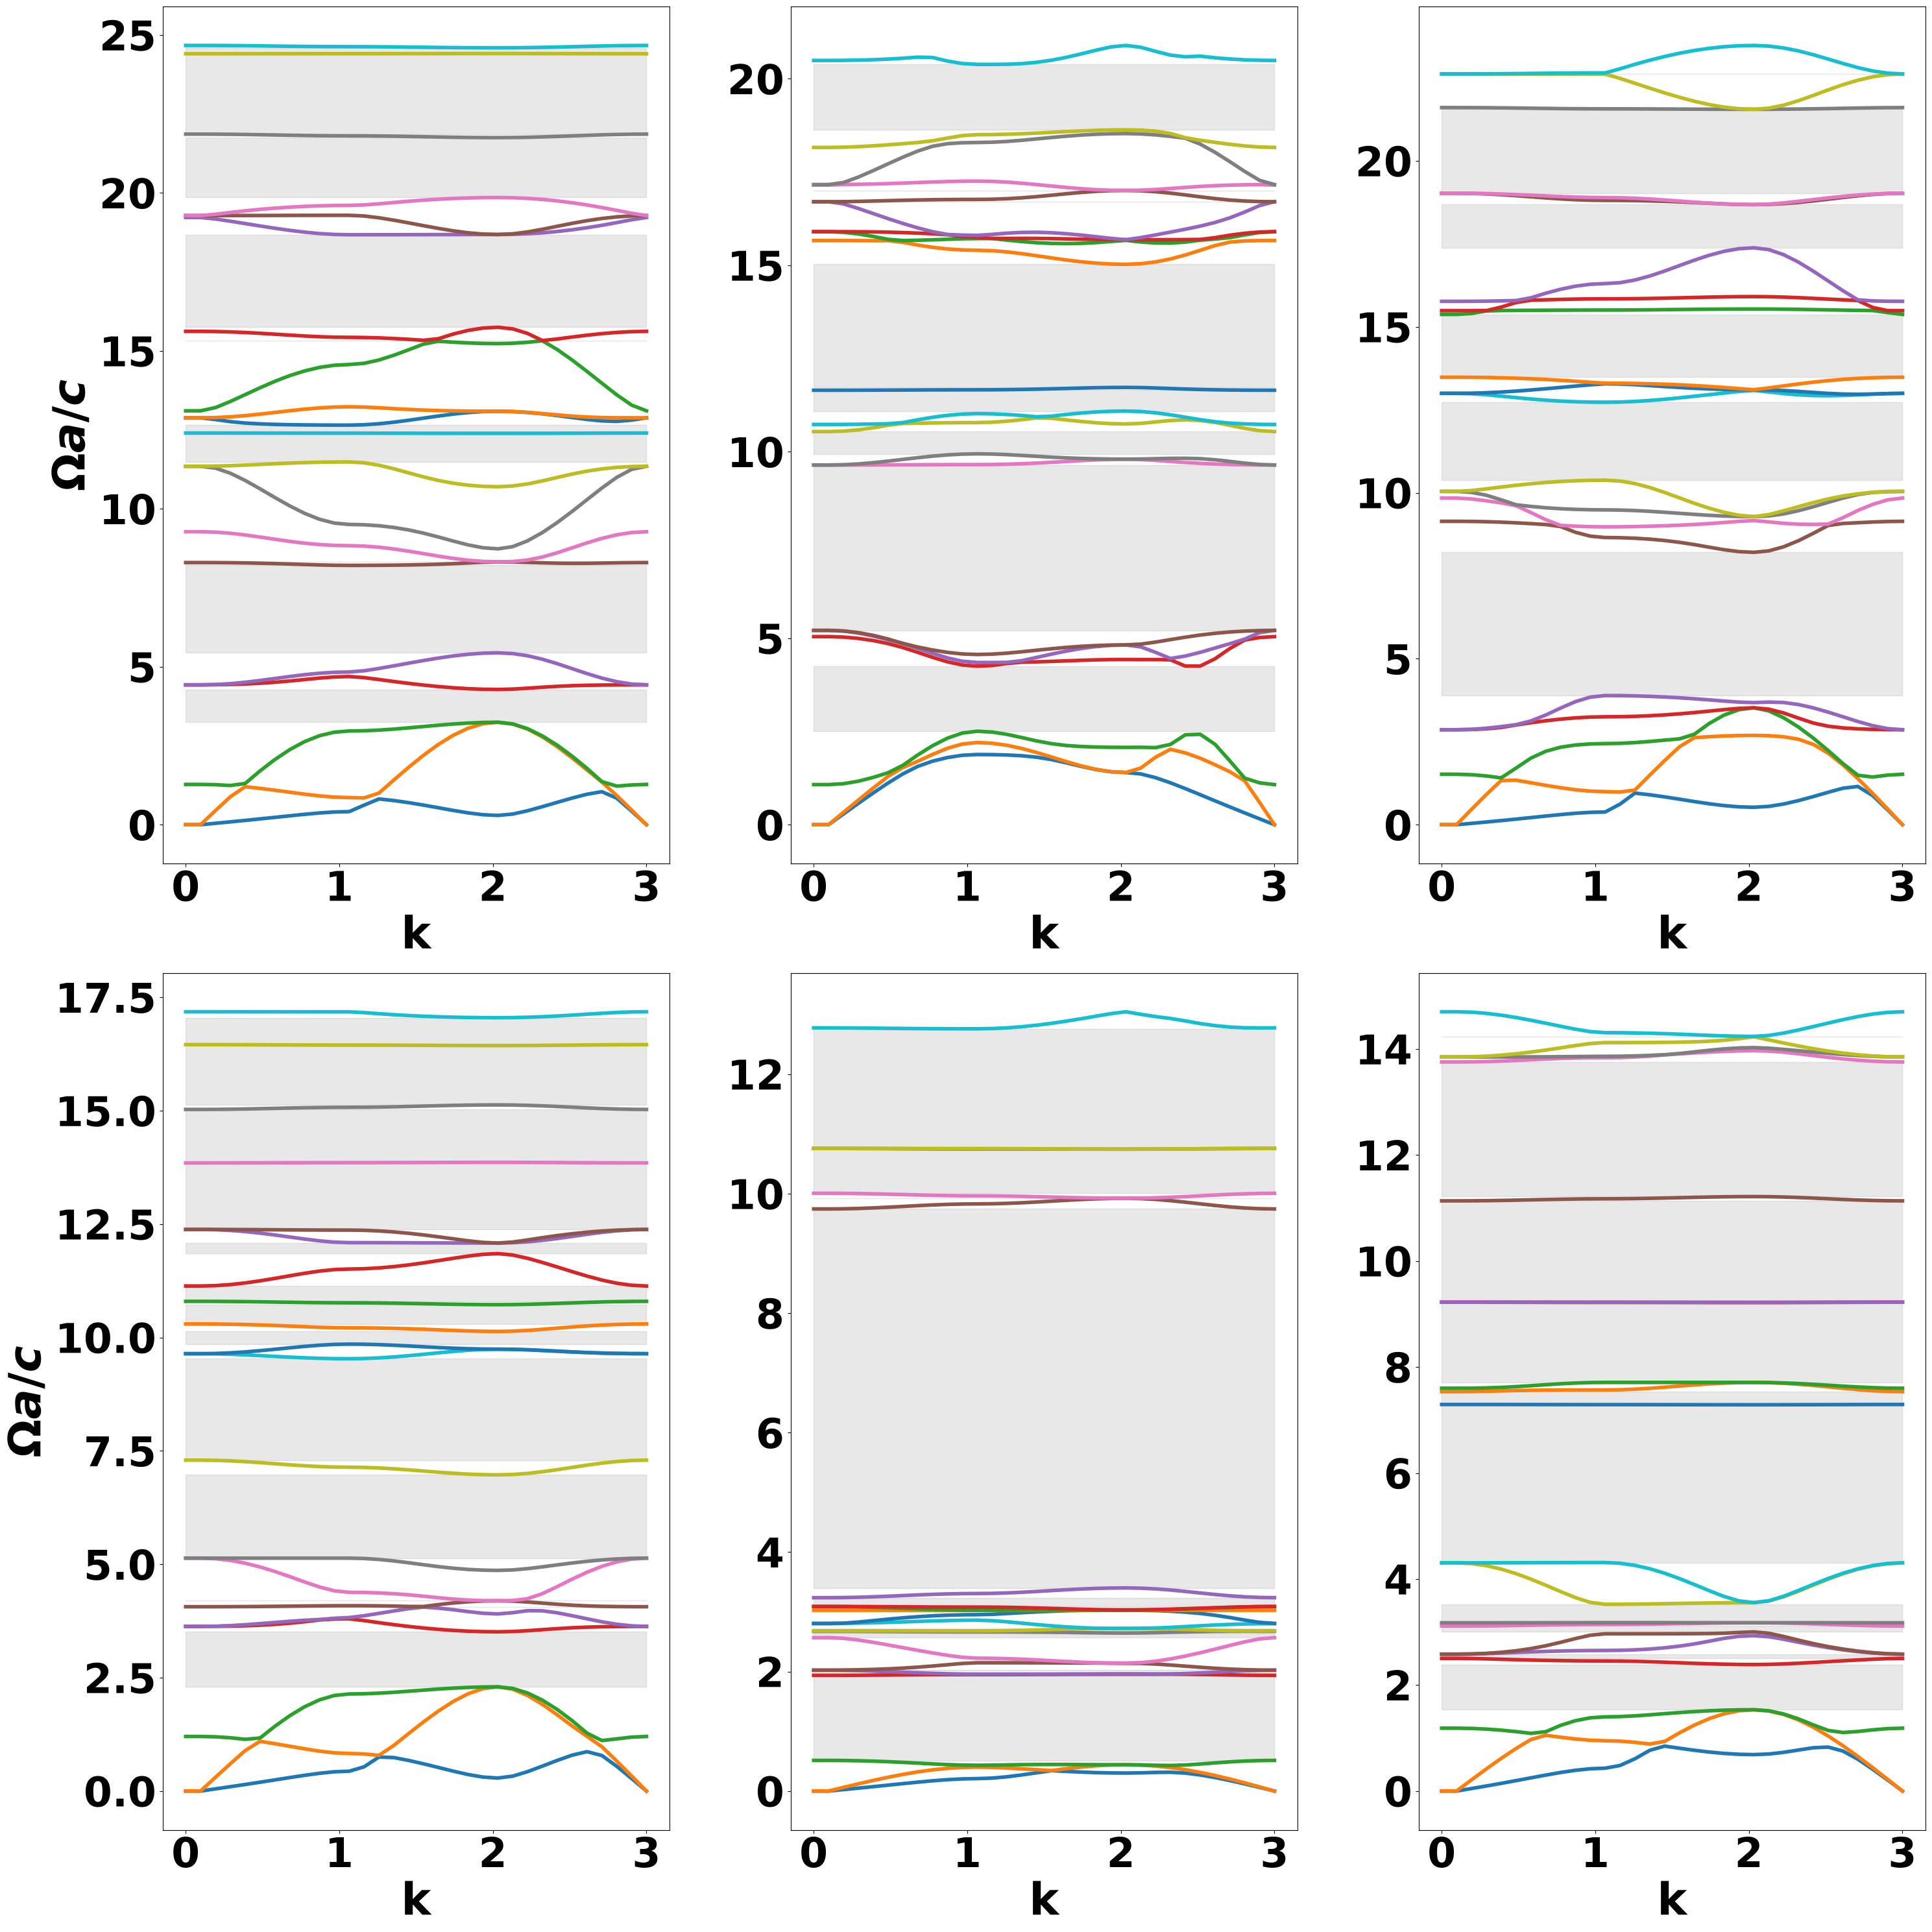

In [48]:
## for trained and evaluated steel on 4 cm
cell4cm = 0.04
reward_train4, states_train4, rx_train4 = select_high_reward_states(trained4cmsteel)
valid_indices = plot_high_reward_structures(states_train4, reward_train4, rx_train4, "trained4cmsteel_states")

for i in rx_train4[:6]:
    vind = plot_targeted_structures(states_train4, reward_train4, [i], f"trained4cmsteel_{i}")

sel_ind4 = rx_train4[:6]
selected_indices = plot_selected_bandstructures(trained4cmsteel, sel_ind4, cell4cm, "trained4cmsteel_bandgaps")

Mean reward: 35.1436


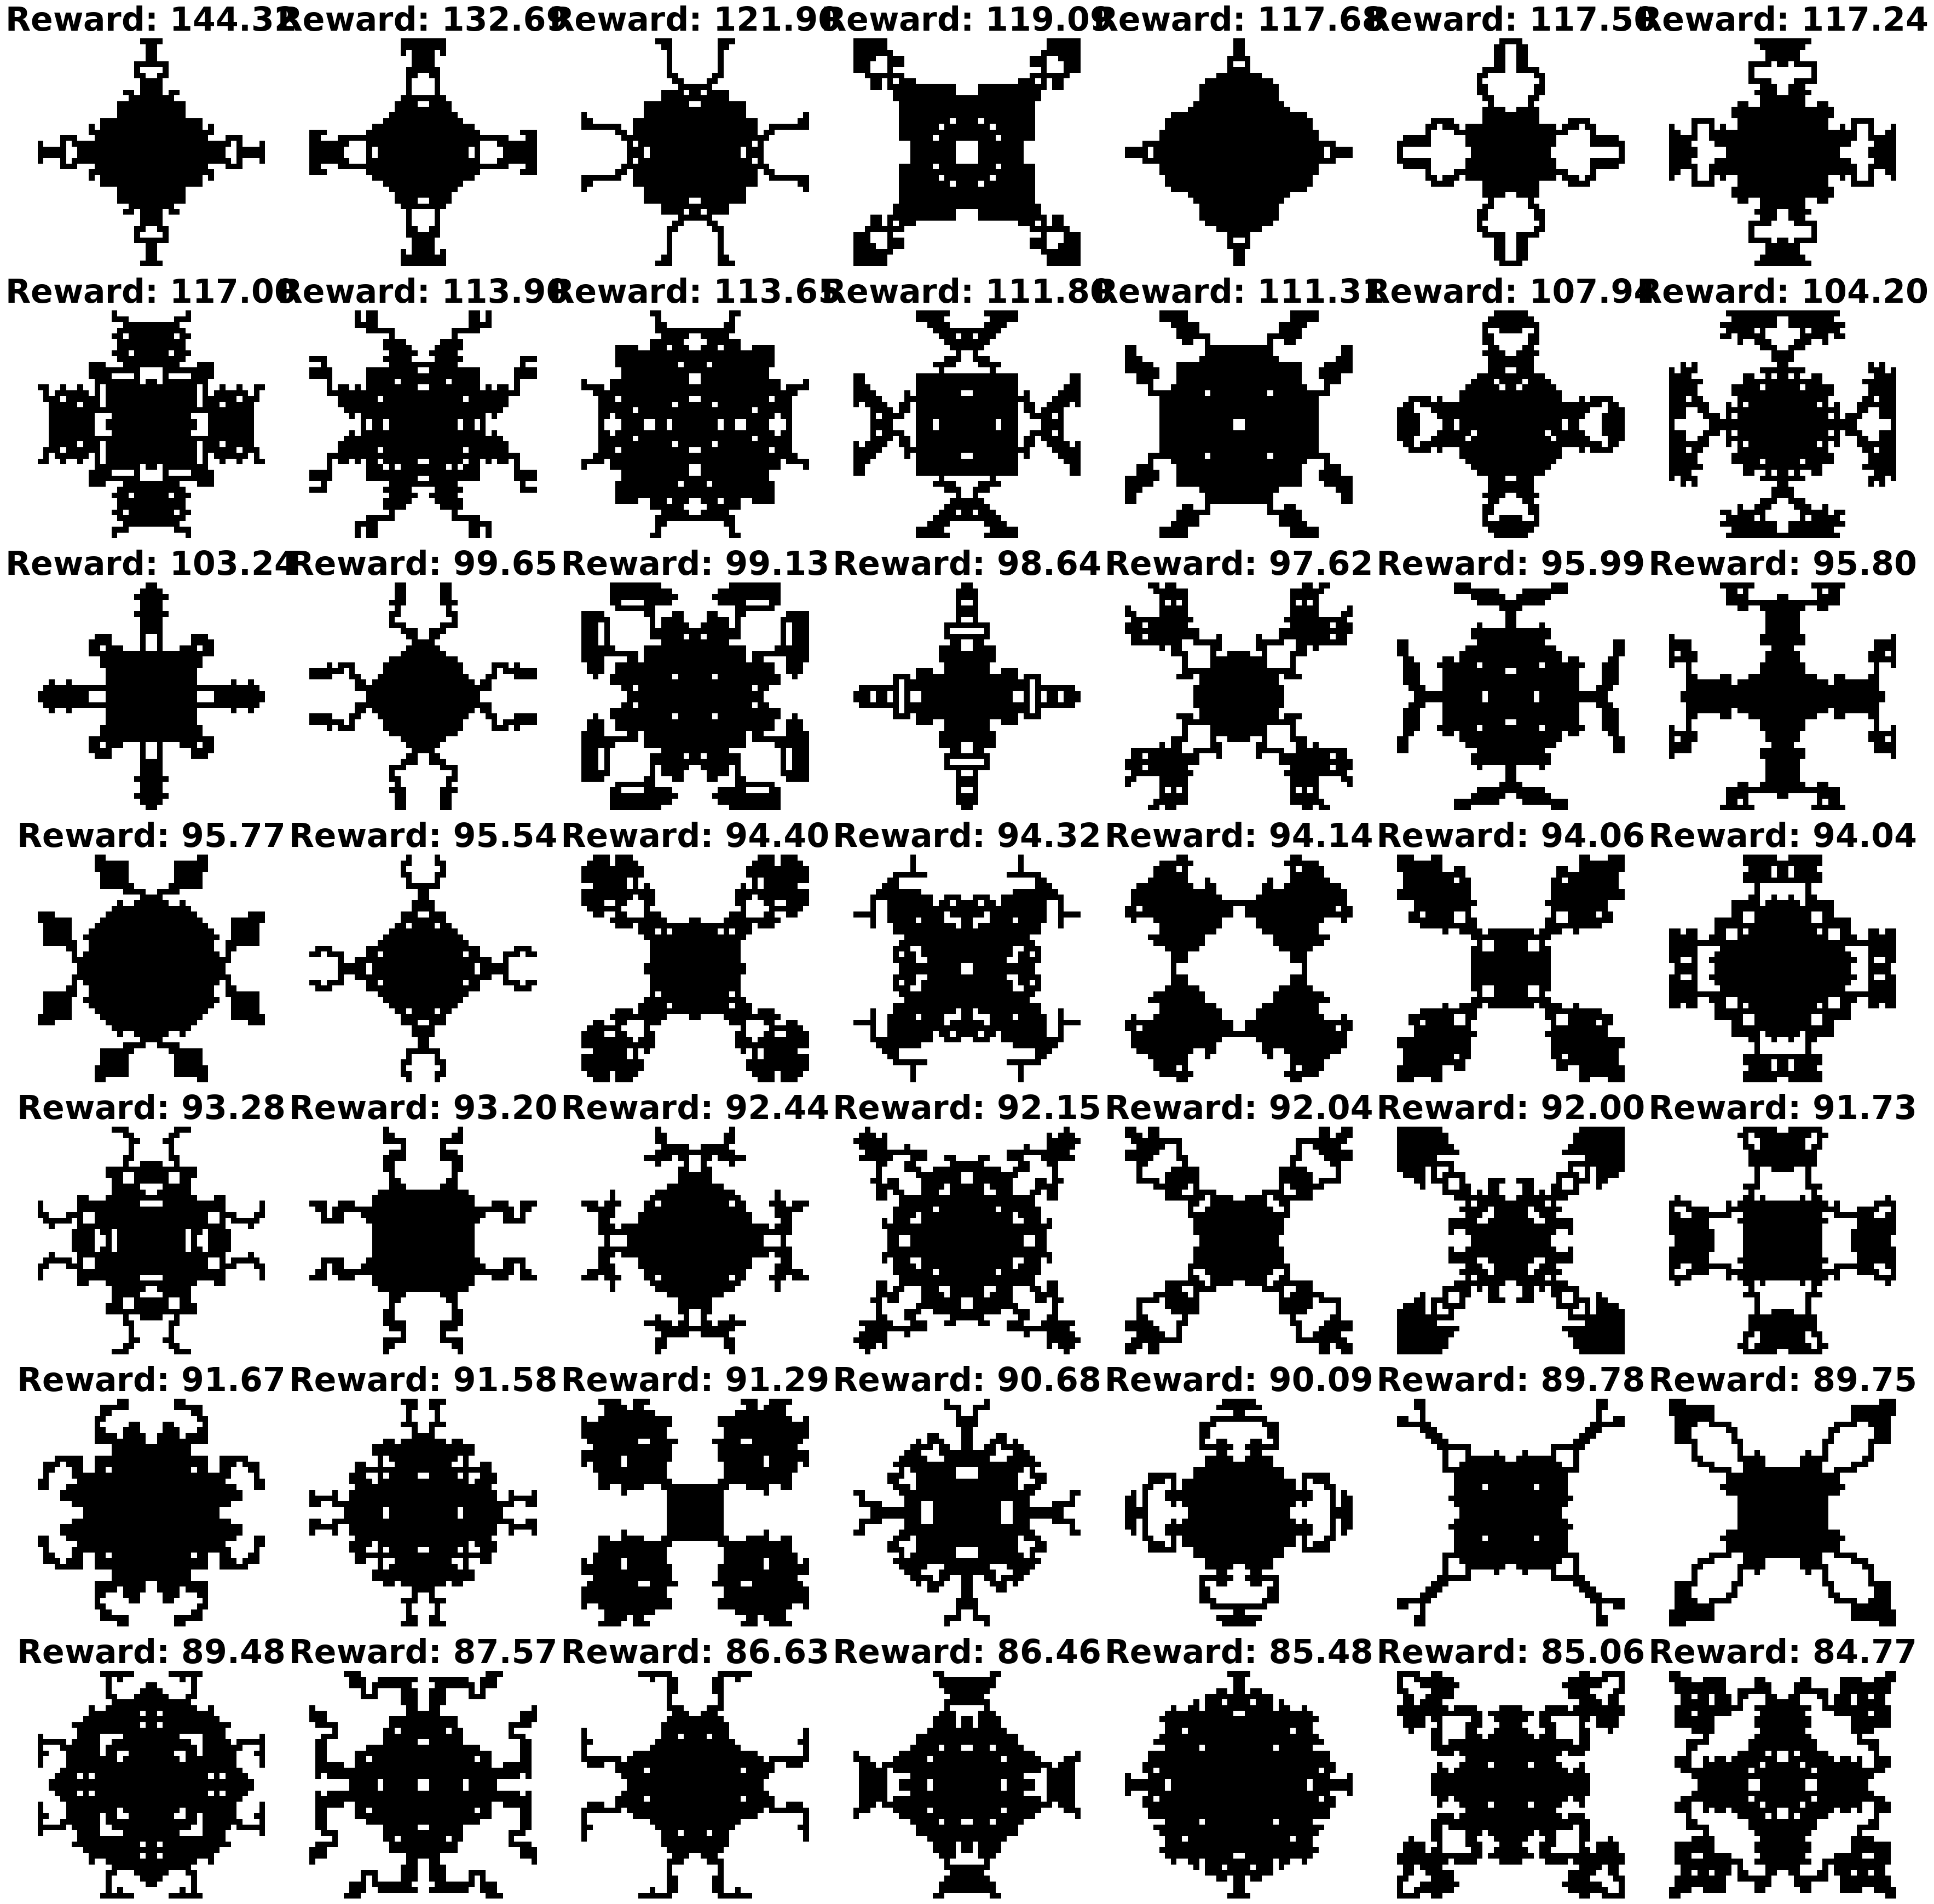

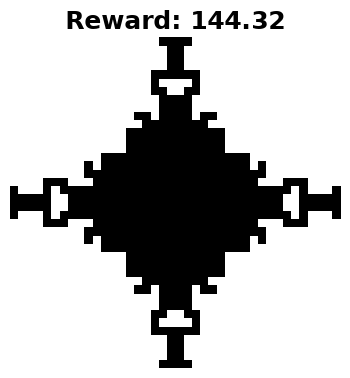

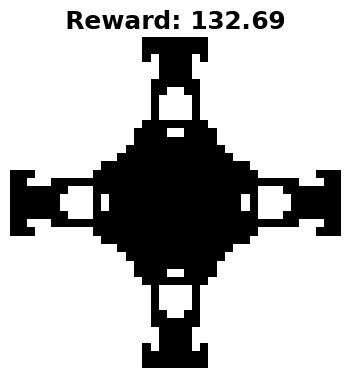

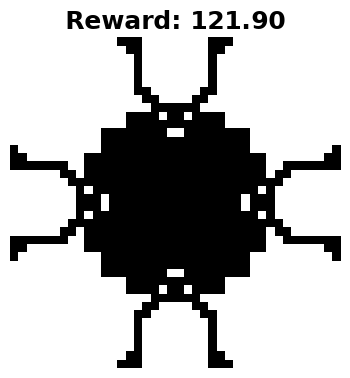

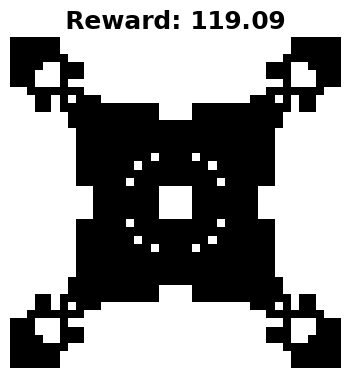

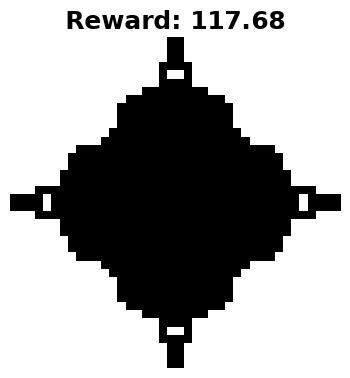

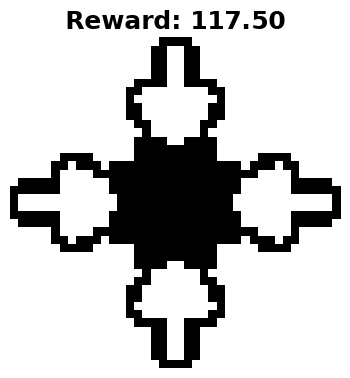

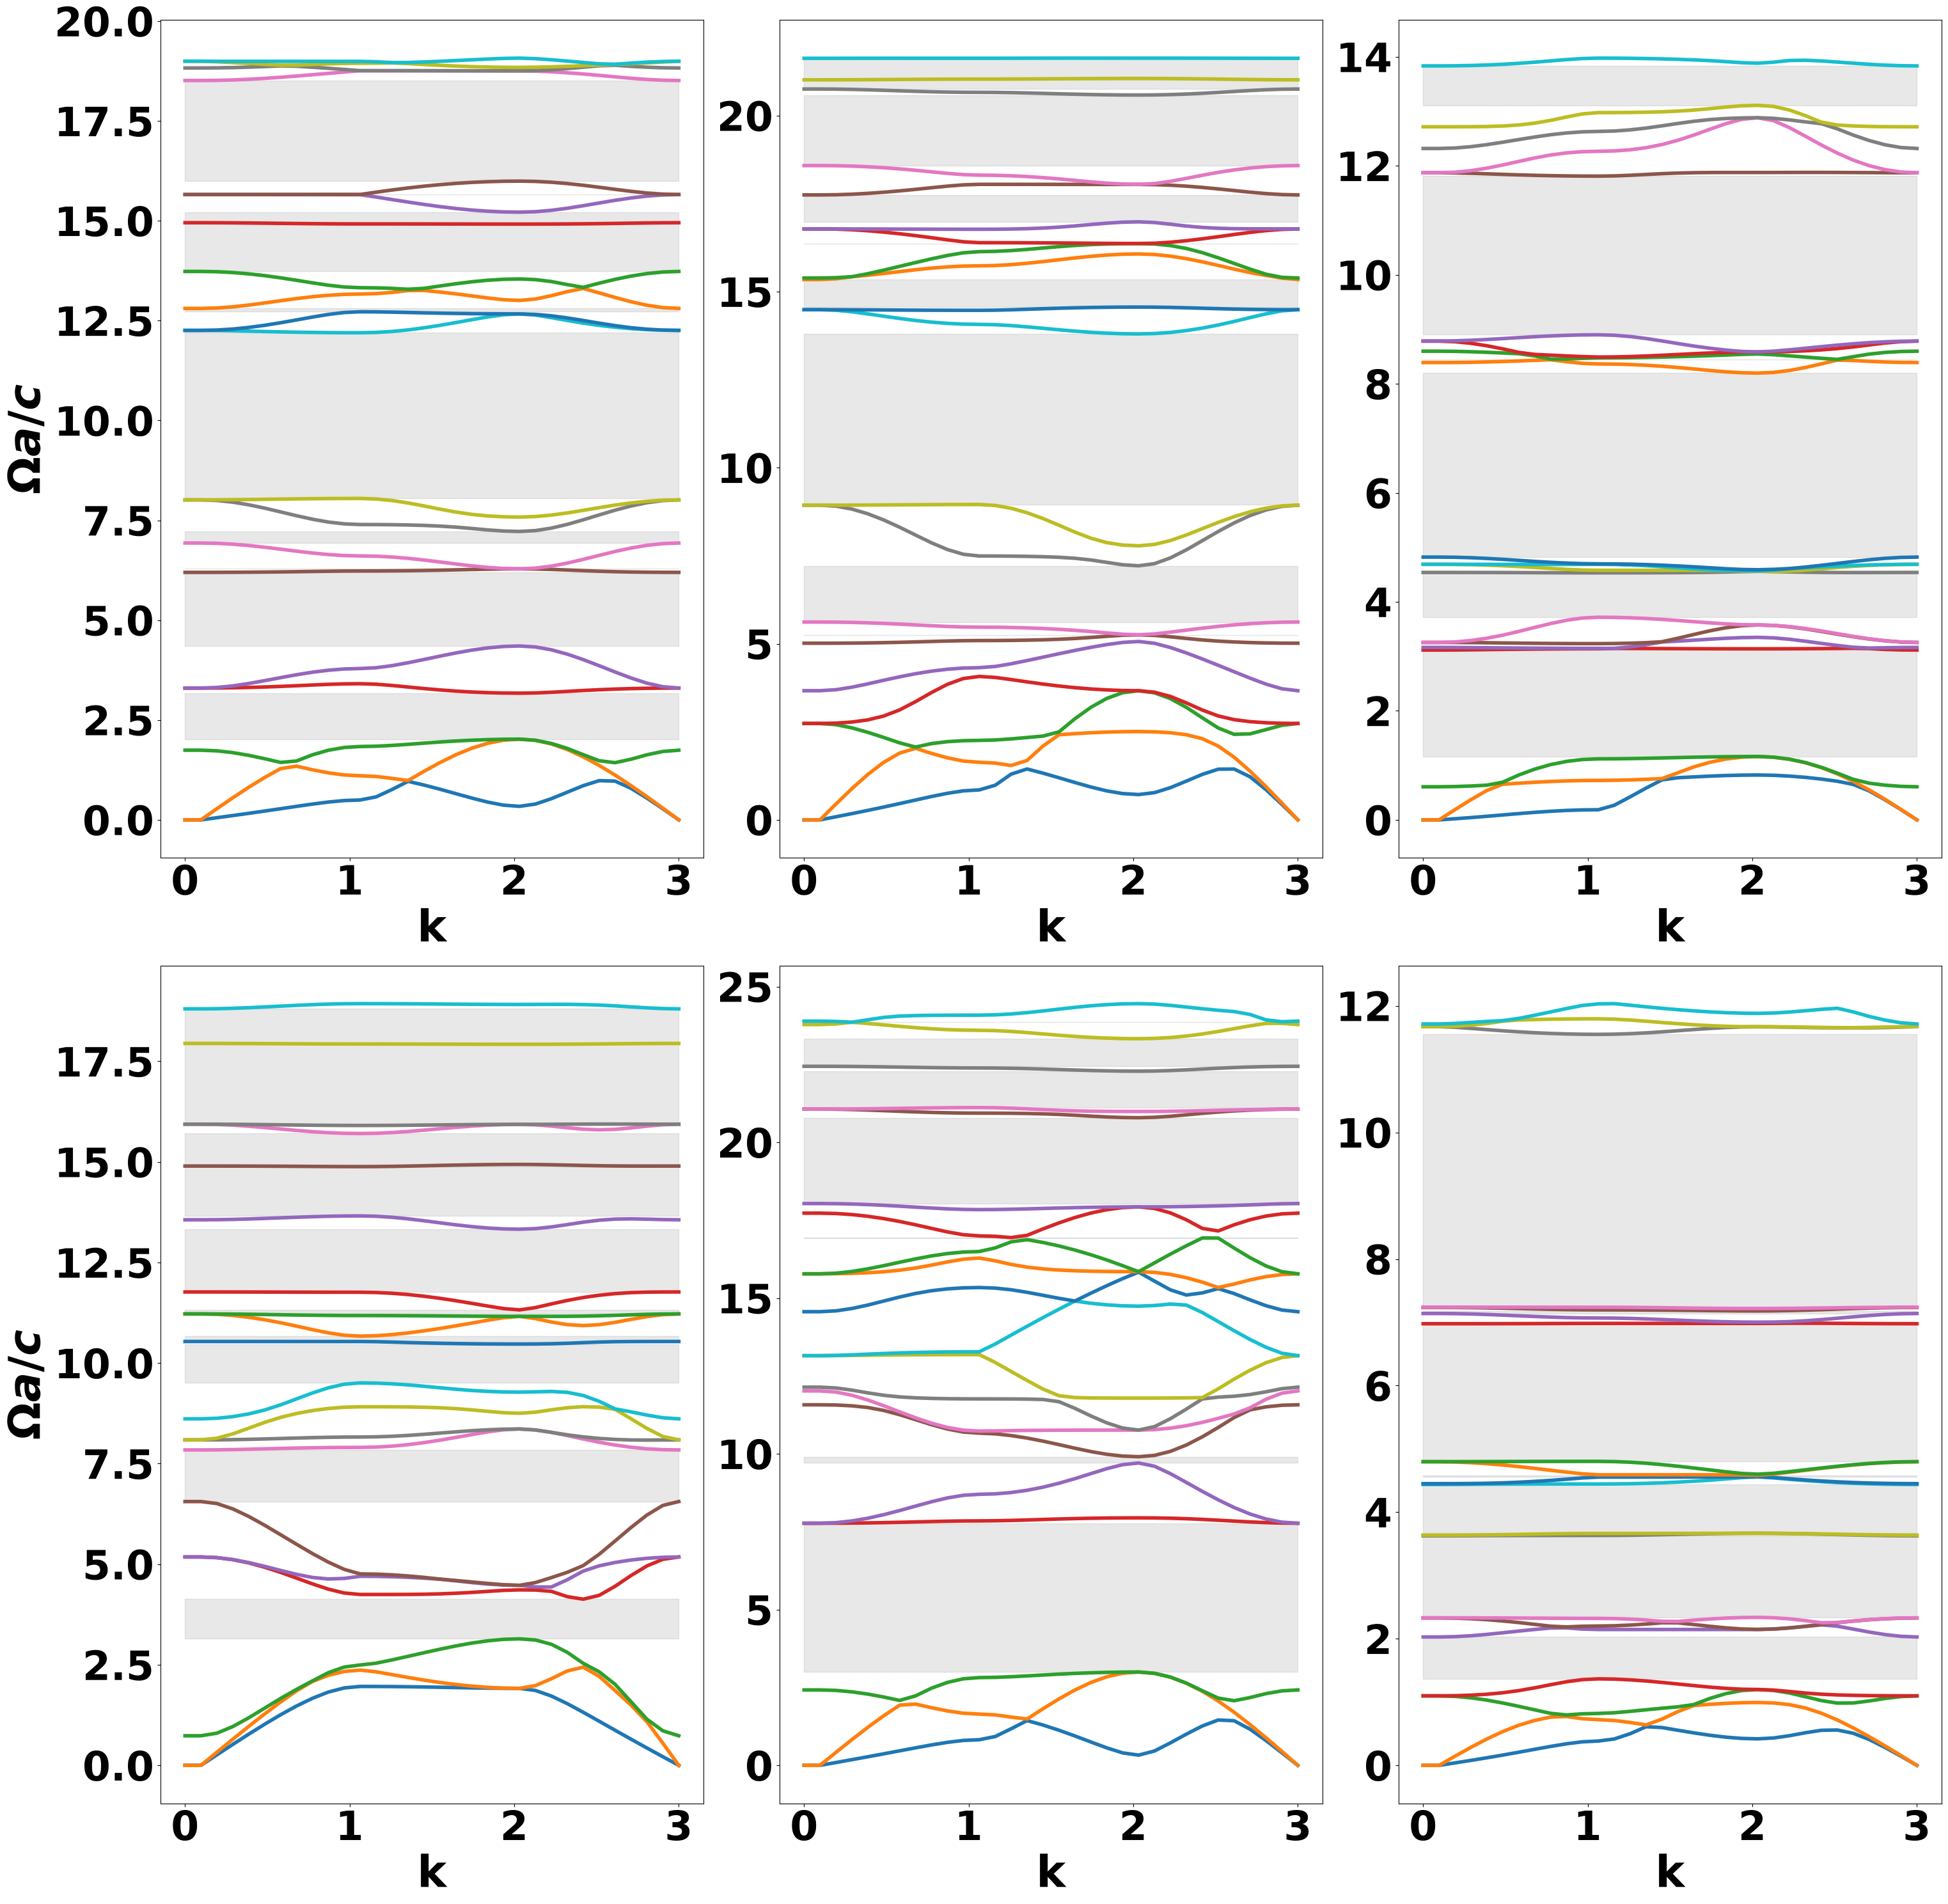

In [49]:
##for evaluated
reward_test4, states_test4, rx_test4 = select_high_reward_states(eval4cm_steel, train=False)
valid_indices_test4 = plot_high_reward_structures(states_test4, reward_test4, rx_test4,"eval4cm_steel_states", train=False)

for i in rx_test4[:6]:
    vind = plot_targeted_structures(states_test4, reward_test4, [i], f"eval4cm_steel_{i}", train=False)

sel_ind_eval4 = rx_test4[:6]
selected_indices = plot_selected_bandstructures(eval4cm_steel, sel_ind_eval4, cell4cm, "eval4cm_steel_bandgaps")

C:\Users\PC\AppData\Local\Temp\ipykernel_14380\3191299651.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False)


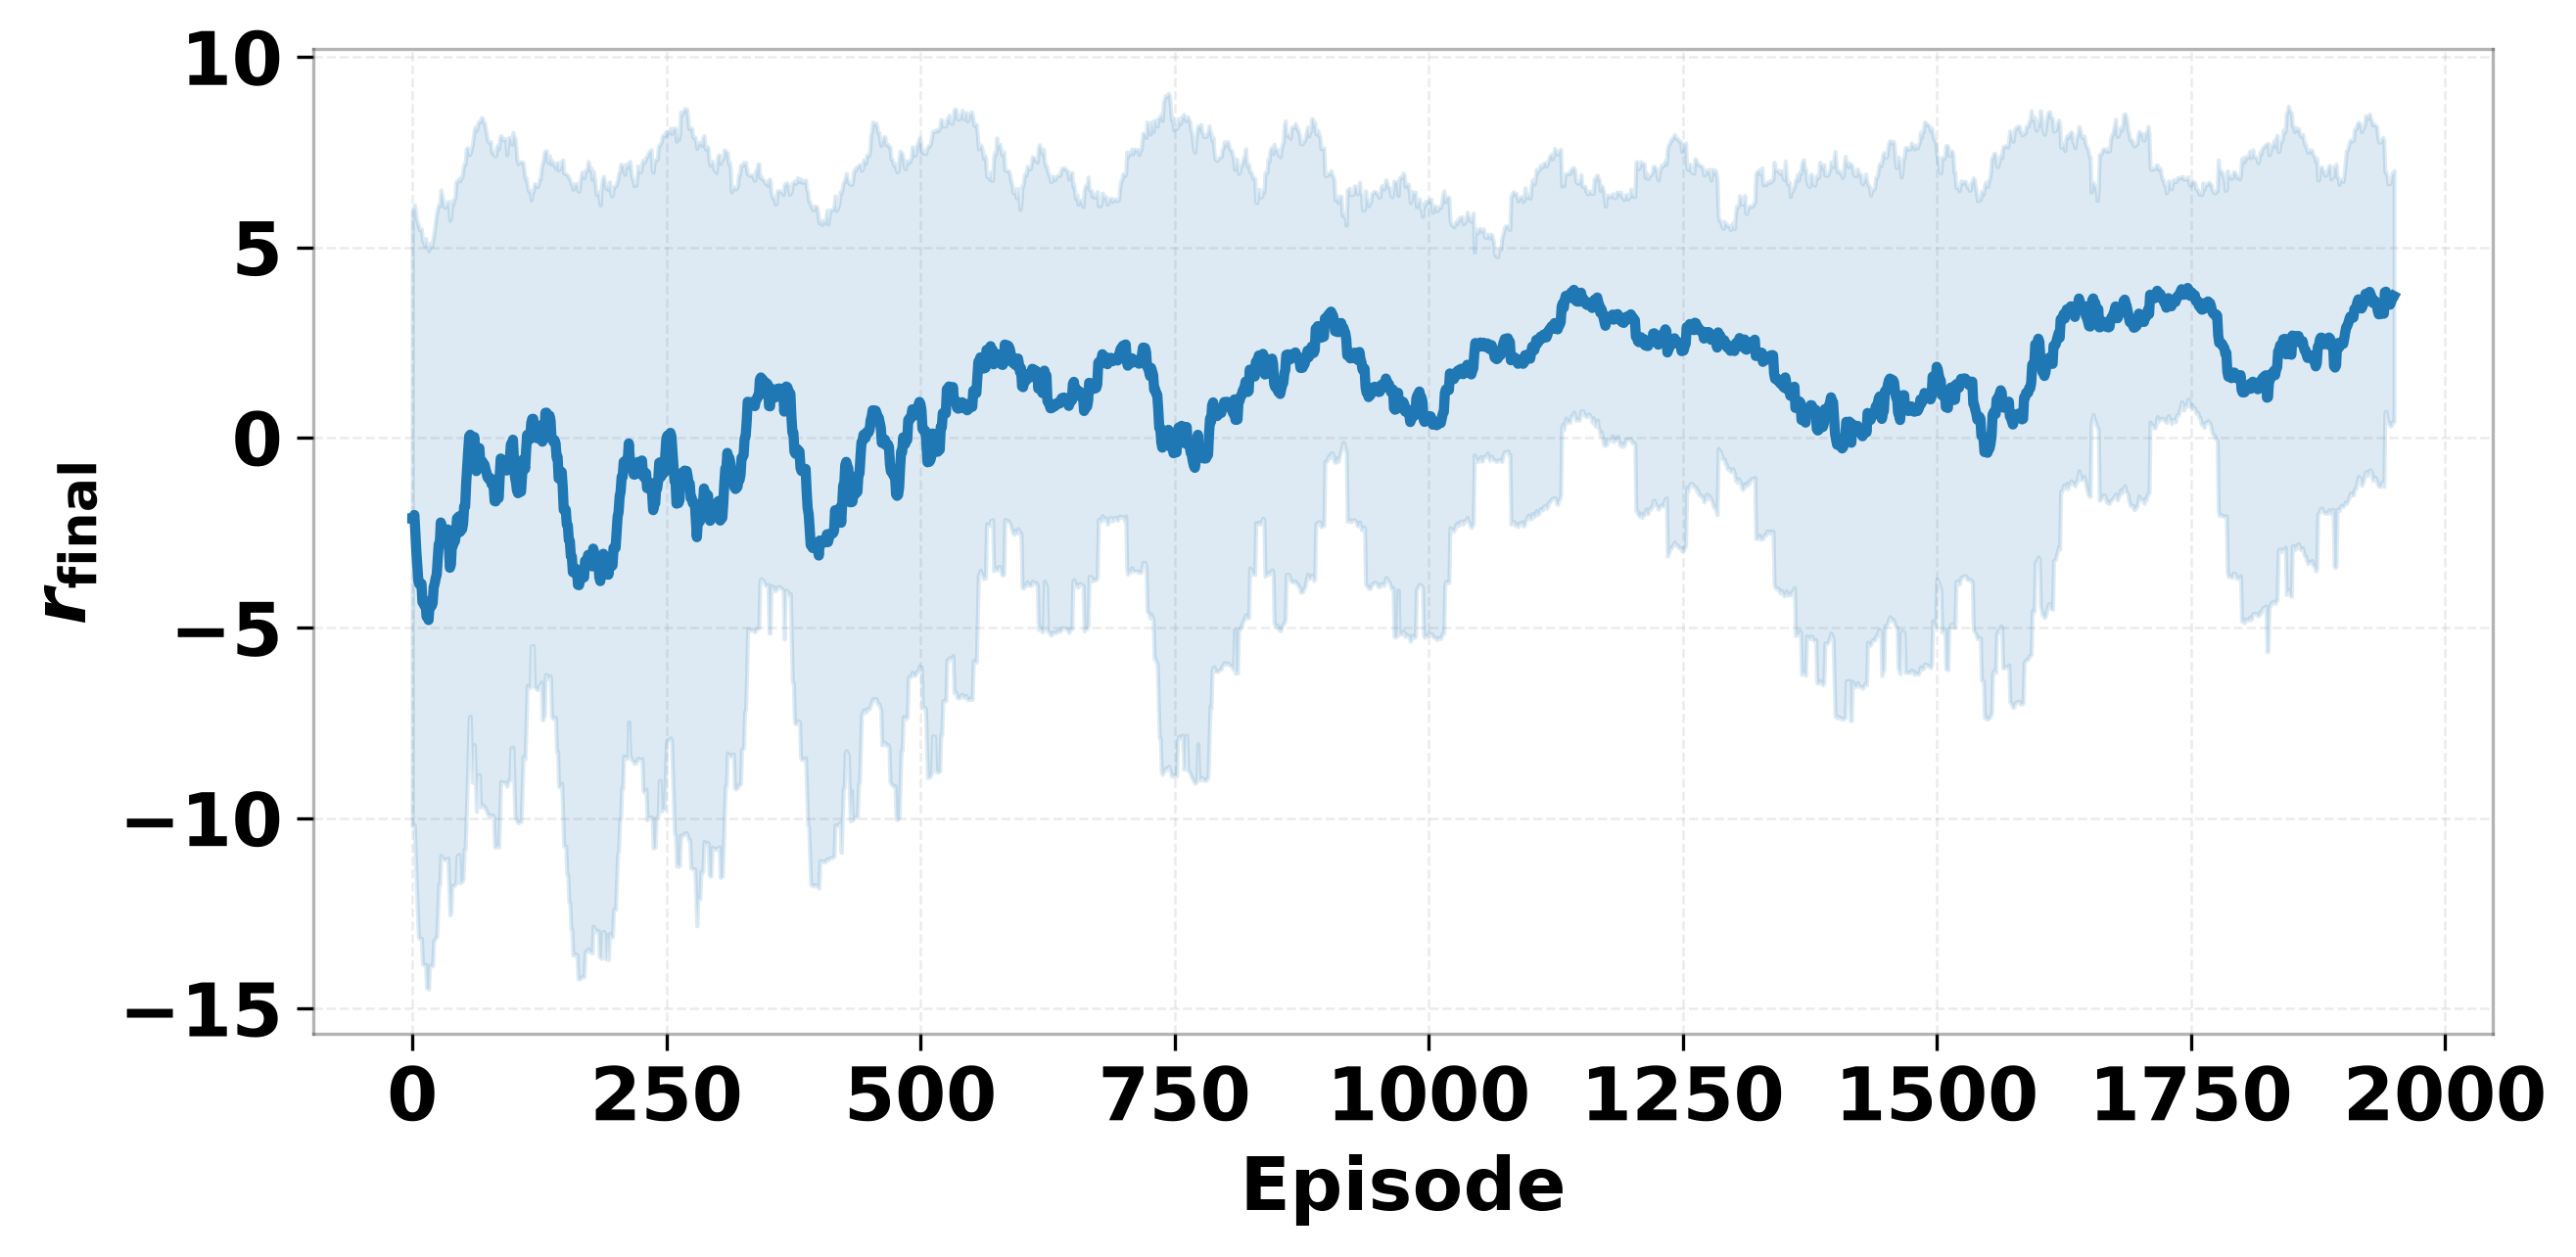

In [36]:
##Original trained(nylon)
def plot_reward_nylon(trained_data, title):
    train_rewards = extract_rewards(trained_data)
    
    window = 50
    train_ma = moving_average(train_rewards, window)
    train_std = moving_std(train_rewards, window)
    
    fig, ax = plt.subplots(figsize=(9, 4.5), dpi=300)
    ax.plot(np.arange(len(train_ma)),train_ma, color="#1f77b4",linewidth=2.5)
    ax.fill_between(np.arange(len(train_ma)), train_ma - train_std, train_ma + train_std, color="#1f77b4", alpha=0.15)
    ax.set_xlabel("Episode", fontsize=18)
    ax.set_ylabel(r"$r_{\mathrm{final}}$", fontsize=18)
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.25)
    
    ax.set_axisbelow(True)
    ax.legend(frameon=False)
    
    for spine in ax.spines.values():
        spine.set_linewidth(0.8)
        spine.set_color("#444444")
        spine.set_alpha(0.4)
    
    ax.tick_params(axis="both", which="major", labelsize=18, length=4, width=0.8)
    ax.tick_params(top=False, right=False)
    plt.tight_layout()
    plt.savefig(f"{title}.png", dpi=500, bbox_inches='tight')
    plt.show()
plot_reward_nylon(trained4cmnylon, "trained4cm_wo_PER")


Mean reward: 1.0843


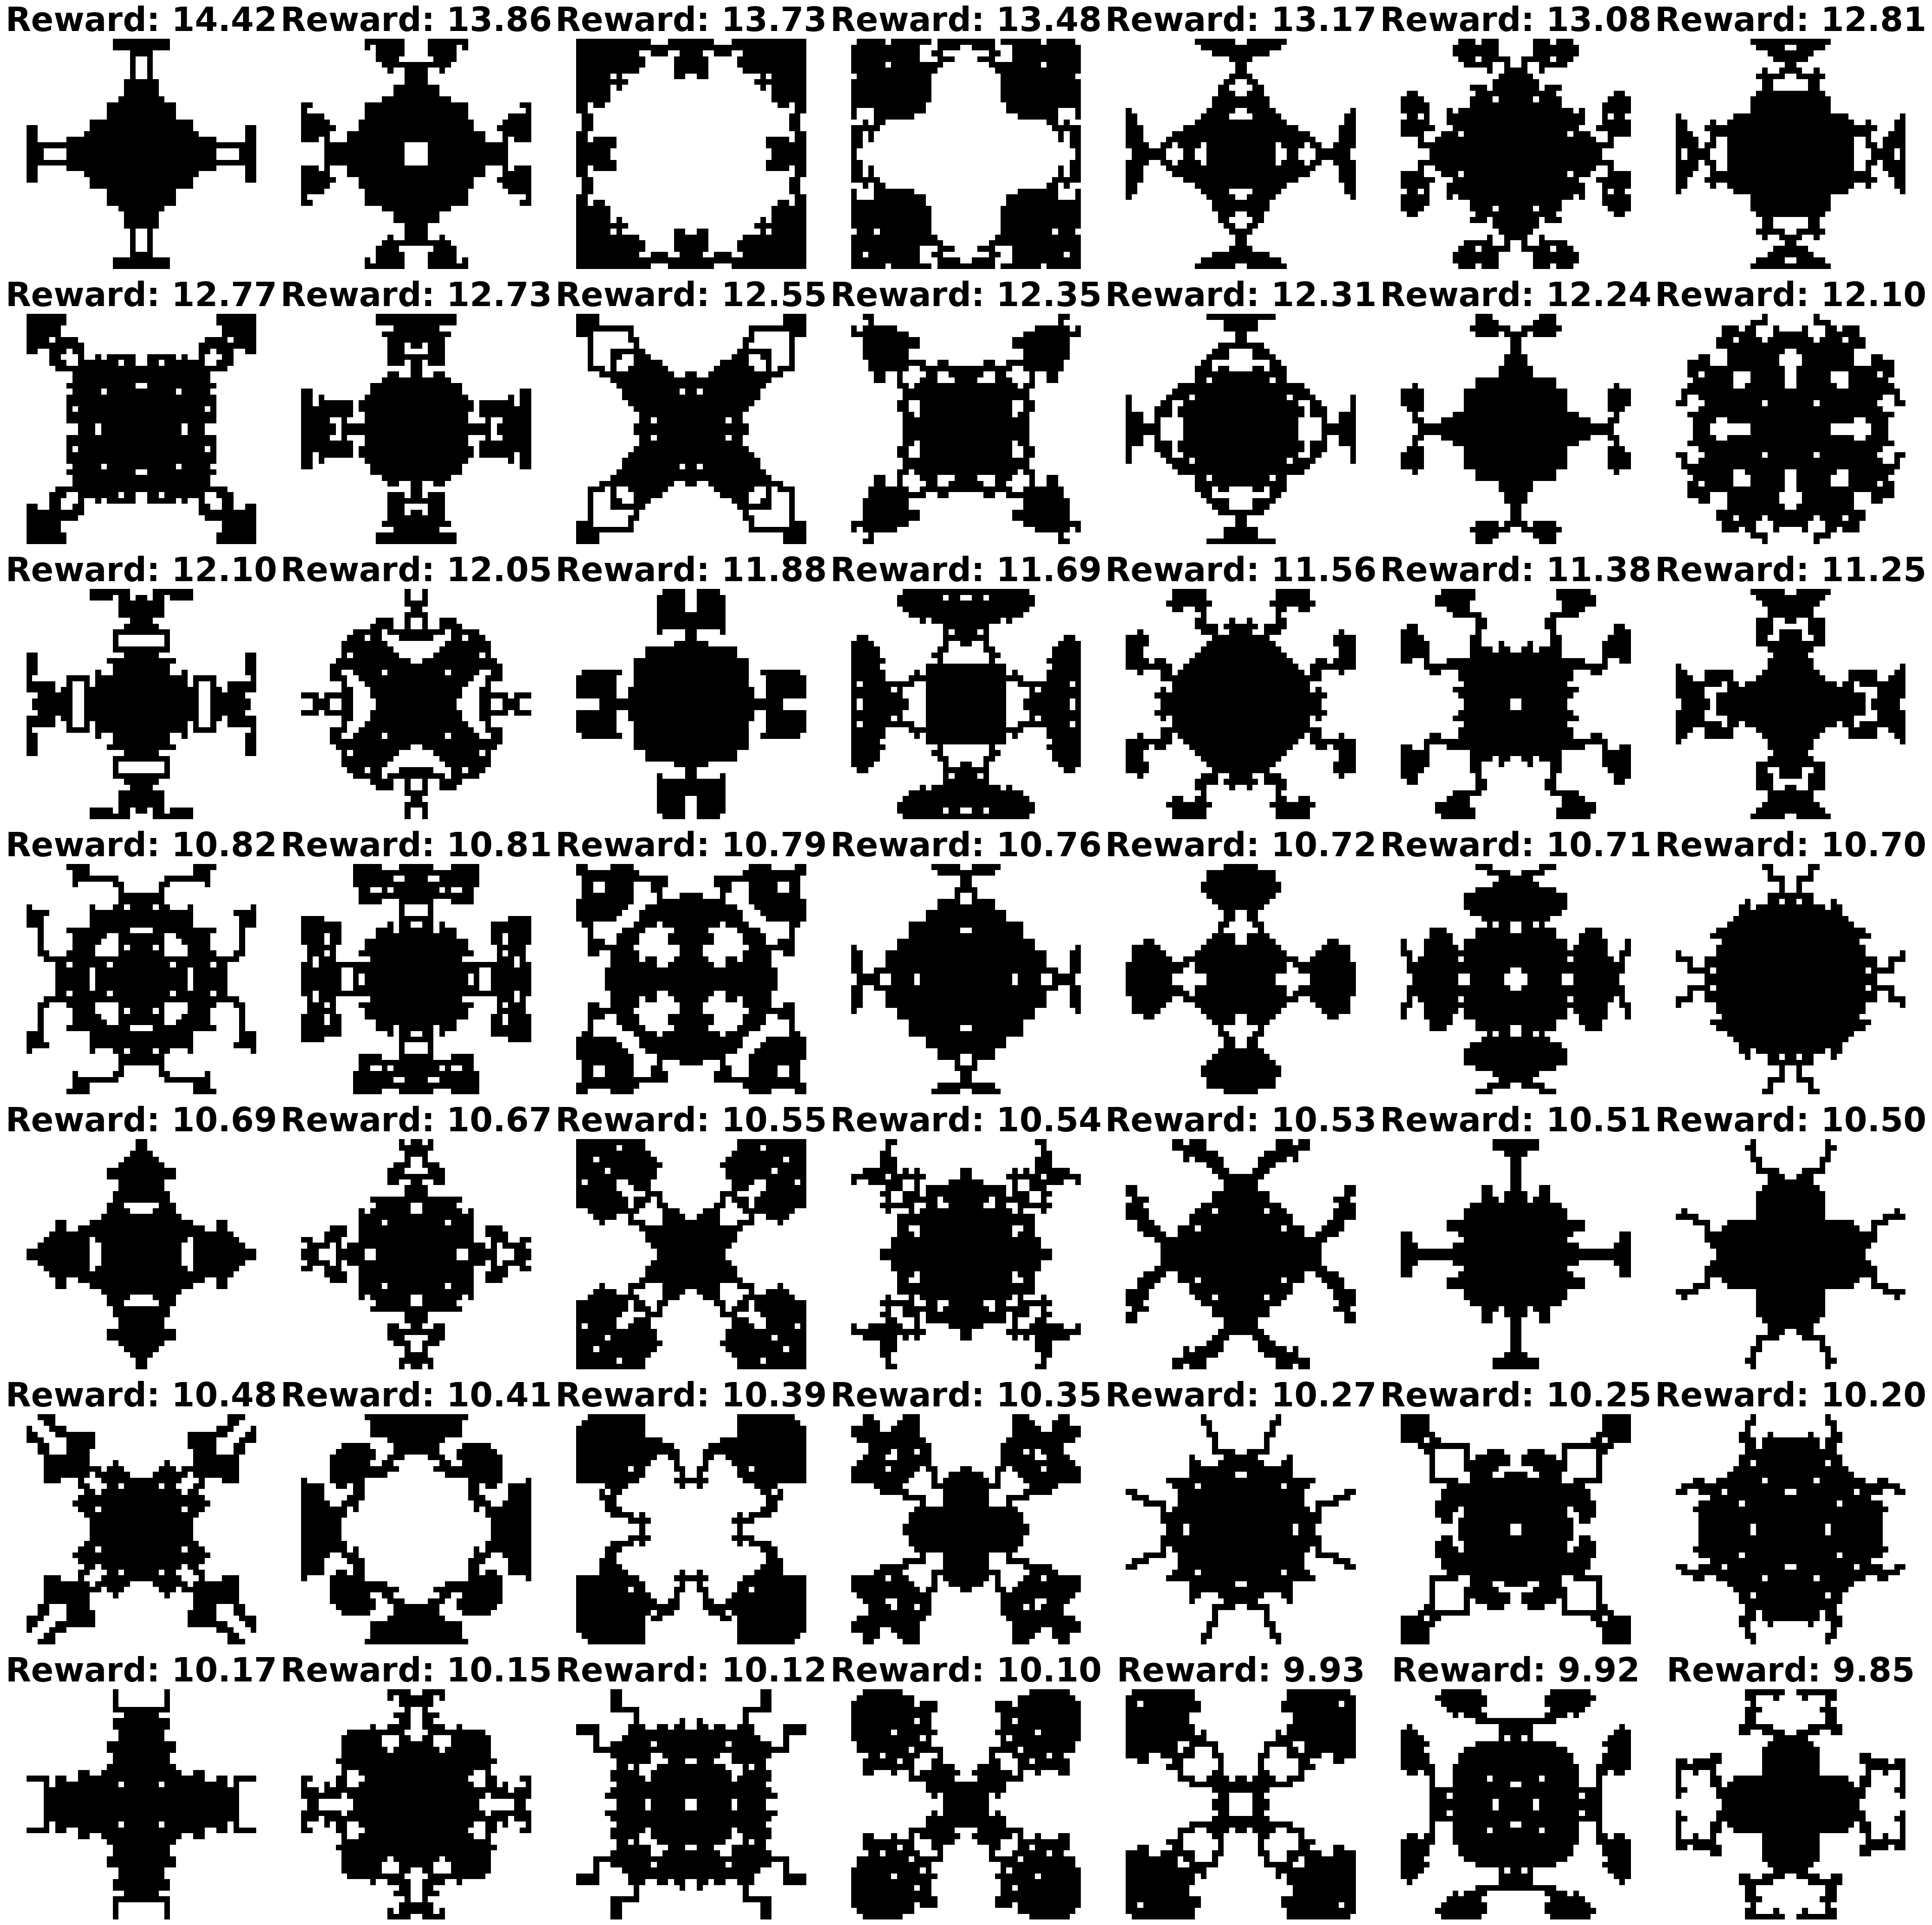

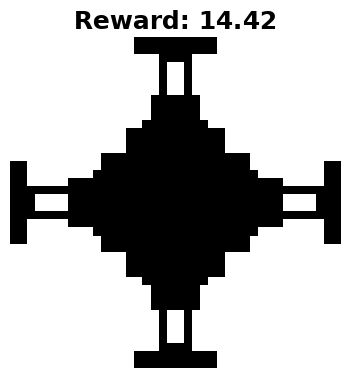

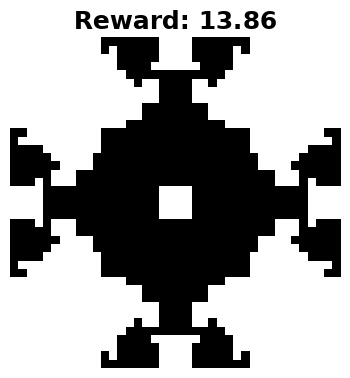

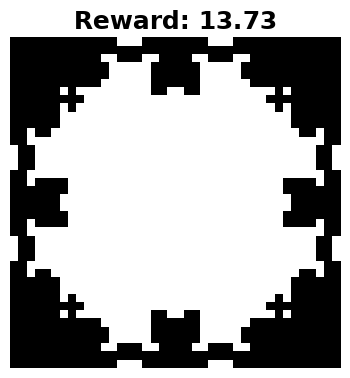

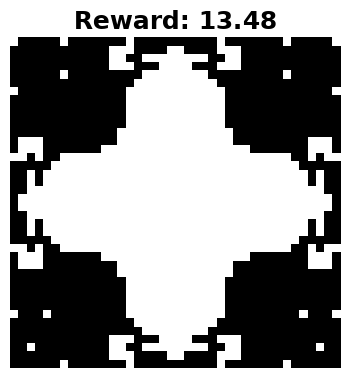

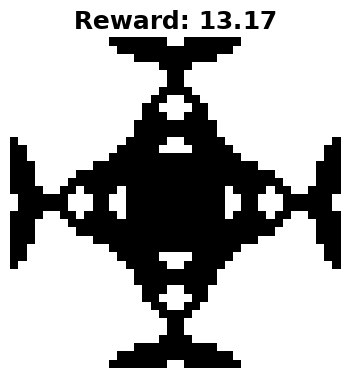

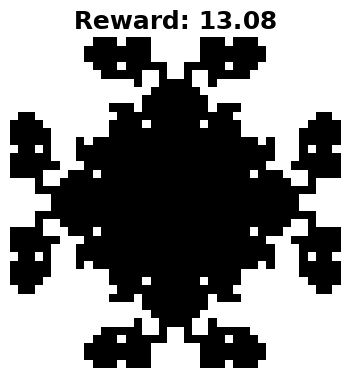

[ 313 1351  235  624  907  788]


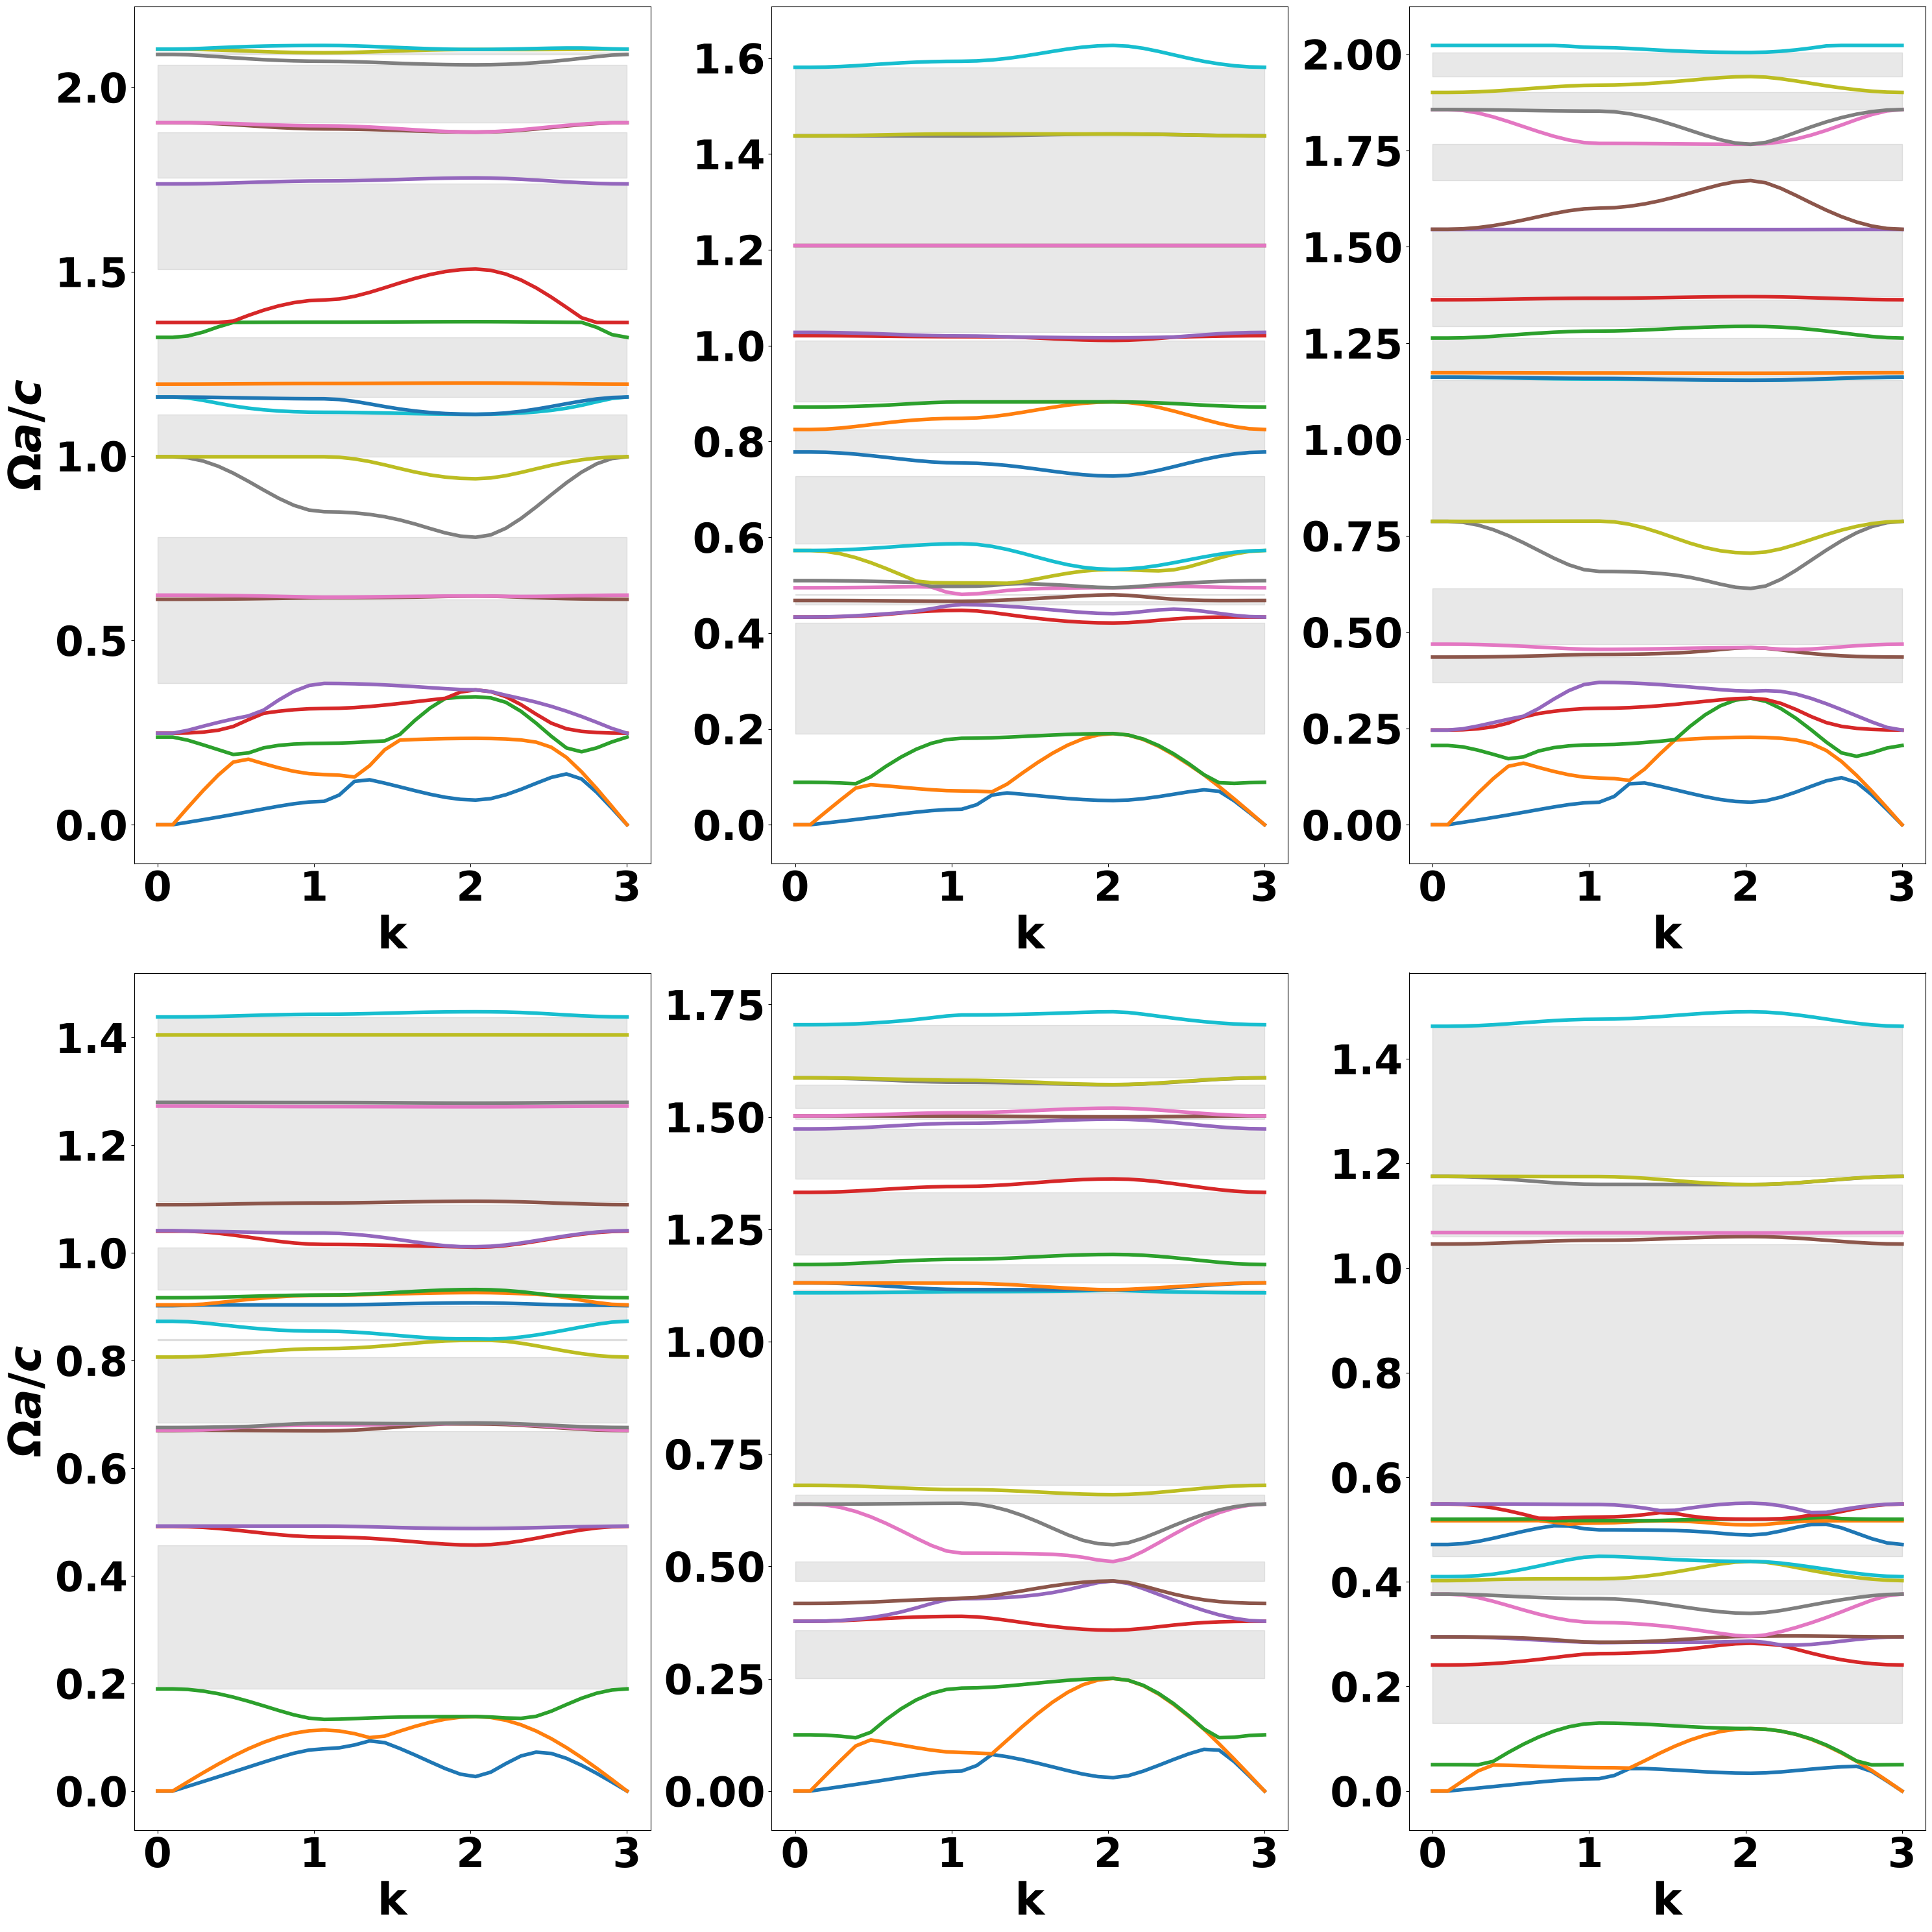

In [50]:
reward_train4_nyl, states_train4_nyl, rx_train4_nyl = select_high_reward_states(trained4cmnylon)
valid_indices_nyl = plot_high_reward_structures(states_train4_nyl, reward_train4_nyl, rx_train4_nyl, "trained4cmnylon_states")

for i in rx_train4_nyl[:6]:
    vind = plot_targeted_structures(states_train4_nyl, reward_train4_nyl, [i], f"trained4cmnylon_{i}")

print(rx_train4_nyl[:6])
sel_ind4_nyl = rx_train4_nyl[:6]
selected_indices = plot_selected_bandstructures(trained4cmnylon, sel_ind4_nyl, cell4cm, "trained4cmnylon_bandgaps")

Mean reward: 1.0843


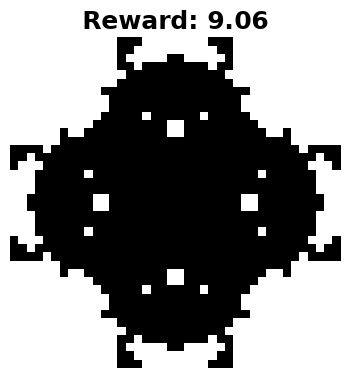

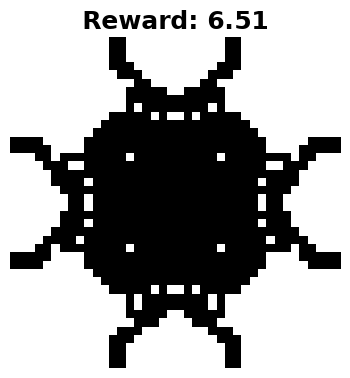

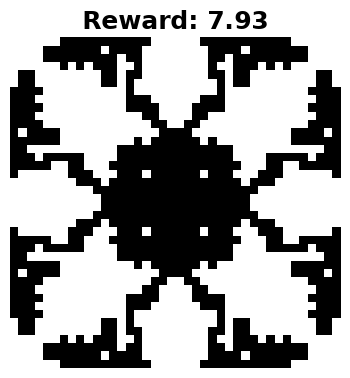

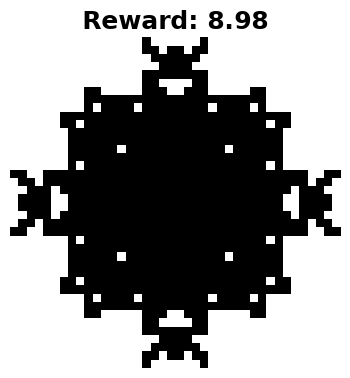

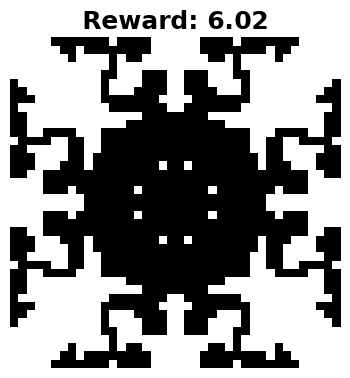

In [51]:
#extracting information from trained model
import numpy as np
import matplotlib.pyplot as plt
from utils.utils import check_4_connectivity_single_component

def select_reward_states(trained_data, train=True):
    if train:
        rewards = np.asarray([val['final_bandgap_reward'] for val in trained_data])
        states = [val['states'] for val in trained_data]
    else:
        rewards = np.asarray([val['final_reward'] for val in trained_data])
        states = [val['fund_grid'] for val in trained_data]

    #candidate_indices = np.where(rewards > np.mean(rewards))[0]
    #selected_indices = np.random.default_rng(seed).choice(candidate_indices, n_samples, replace=False)

    print(f"Mean reward: {np.mean(rewards):.4f}")
    return rewards, states

def reconstruct_structure(state, train=True):
    if train:
        path = np.unique(np.asarray(state, dtype=int), axis=0)
        grid = get_fundamental_grid(20, path)
        grid = strictly_enforce_4_connectivity(build_p4m_structure_simple(grid))
        is_connected, _ = check_4_connectivity_single_component(grid)
    else:
        grid = np.asarray(state).reshape(20, 20)
        grid = strictly_enforce_4_connectivity(build_p4m_structure_simple(grid))
        is_connected, _ = check_4_connectivity_single_component(grid)
        
    return grid, is_connected
    
def plot_targeted_structures(states, rewards, selected_indices, title, train=True):
    fig, ax = plt.subplots(figsize=(4, 4))
    #axes = axes.flatten()
    valid_indices = []
    for idx in selected_indices:
        grid, is_connected = reconstruct_structure(states[idx], train)
        if is_connected:
            ax.imshow(grid, cmap="gray", origin="lower")
            ax.set_title(f"Reward: {rewards[idx]:.2f}", fontsize=18, fontweight='bold')
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(f"{title}.png", dpi=500, bbox_inches='tight')
    plt.show()
    return valid_indices

def plot_selected_bandstructures(trained_data, selected_indices, cell_size, title):
    bandgaps = [np.asarray(val['bandgap']) for val in trained_data]
    k = np.linspace(0, 3, 32)
    plt.rcParams.update({"font.size": 14, "axes.titlesize": 14, "axes.labelsize": 14, "legend.fontsize": 14, "lines.linewidth": 2})
    fig, axes = plt.subplots(1, 5, figsize=(12, 4))
    axes = axes.flatten()
    for i, (ax, idx) in enumerate(zip(axes, selected_indices)):
        data_sorted = np.sort(bandgaps[idx] * cell_size / 343, axis=1)
        ax.plot(k, data_sorted, linewidth=4)
        for b in range(data_sorted.shape[1] - 1):
            lower, upper = data_sorted[:, b], data_sorted[:, b + 1]
            gap_lower, gap_upper = np.max(lower), np.min(upper)
            if gap_upper > gap_lower:
                ax.fill_between(k, gap_lower, gap_upper, color="gray", alpha=0.18)
        ax.set_xlabel("k", fontsize=10)
        ax.set_ylabel(r"$\Omega a/c$" if i % 6 == 0 else "", fontsize=10)
        ax.tick_params(axis="both", labelsize=15)
        #ax.set_title(f"Structure {idx}", fontsize=25)
    plt.tight_layout()
    plt.savefig(f"{title}.png", dpi=500, bbox_inches='tight')
    plt.show()
    return selected_indices

tx_train = [759, 821, 1054, 1657, 1861]
rew4, states = select_reward_states(trained4cmnylon)
# sel_ind4_nyl = rx_train4_nyl[:6]
for i in tx_train:
    valid_indices = plot_targeted_structures(states, rew4, [i], cell4cm, f"trained4cmnylon_state{i}")

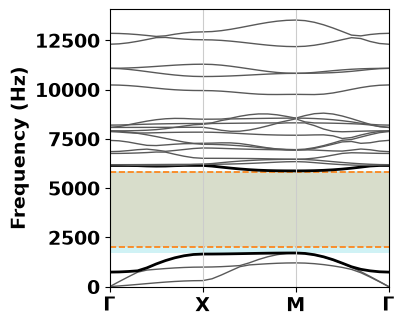

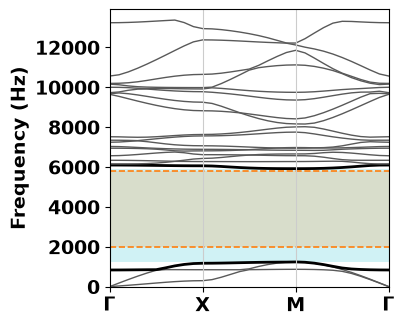

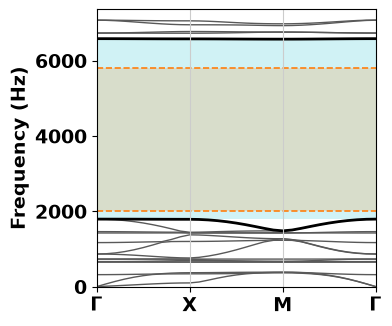

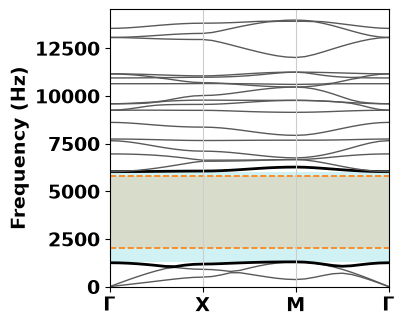

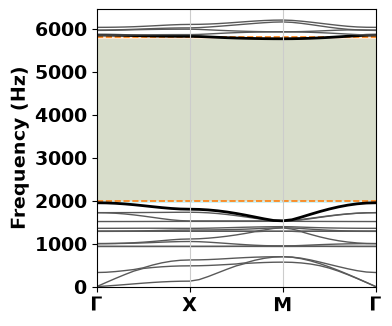

In [43]:
def band_data(entry):
    """31 x 20 band array as plotted in the app (None if the episode was not simulated)."""
    b = np.real(np.asarray(entry['bandgap']))
    if b.ndim != 2:
        return None
    return b[1:] if b.shape[0] == 32 else b          # drop the duplicate first row

def gaps(bands):
    """All complete gaps: (n, lower edge, upper edge, gap-to-midgap ratio), n = 1-based lower band."""
    out = []
    for i in range(bands.shape[1] - 1):
        L, U = bands[:, i].max(), bands[:, i + 1].min()
        if U > L:
            out.append((i + 1, L, U, 2 * (U - L) / (U + L)))
    return out

def pick_gap(bands, f_lo=None, f_hi=None):
    """Gap highlighted by the app: best coverage of [f_lo, f_hi]; widest ratio if no target is given."""
    g = gaps(bands)
    if not g:
        return None
    if f_lo is None:
        return max(g, key=lambda x: x[3])
    w = f_hi - f_lo
    cov  = lambda x: max(0.0, min(x[2], f_hi) - max(x[1], f_lo)) / w
    dist = lambda x: (abs(x[1] - f_lo) + abs(x[2] - f_hi)) / w
    return max(g, key=lambda x: (cov(x), -dist(x)))

def plot_dispersion(entry, f_lo=None, f_hi=None, scale=1.0, ax=None, title=None):
    bands = band_data(entry)
    if bands is None:
        print(f"Episode {entry['episode']}: disconnected, no band data"); return
    bands = bands * scale
    k = np.linspace(0, 3, bands.shape[0])            # Gamma-X-M-Gamma, k = 0..3
    ax = ax or plt.subplots(figsize=(3.6, 3.6))[1]
    g = pick_gap(bands, f_lo, f_hi)
    if g:
        n, L, U, ratio = g
        ax.axhspan(L, U, color="tab:cyan", alpha=0.2, lw=0)
        #ax.set_title(f"Episode {entry['episode']}: bands {n}-{n+1}, "
        #             f"{L:,.0f}-{U:,.0f} Hz, ratio {ratio:.3f}", fontsize=10)
    if f_lo is not None:
        ax.axhspan(f_lo, f_hi, color="tab:orange", alpha=0.18, lw=0)
        for f in (f_lo, f_hi):
            ax.axhline(f, color="tab:orange", ls="--", lw=1.2)
    for j in range(bands.shape[1]):
        edge = g is not None and j in (g[0] - 1, g[0])
        ax.plot(k, bands[:, j], color="k" if edge else "0.35", lw=2 if edge else 1)
    for x in (1, 2):
        ax.axvline(x, color="0.8", lw=0.8)
    ax.set_xticks([0, 1, 2, 3], [r"$\Gamma$", "X", "M", r"$\Gamma$"])
    ax.set_xlim(0, 3); ax.set_ylim(0, bands.max() * 1.04)
    ax.set_ylabel("Frequency (Hz)")
    #plt.savefig(f"{title}.png", dpi=500, bbox_inches='tight')
    return ax

# same episode as the app's "Episode 761", with the app's default target range
for i in tx_train:
    plot_dispersion(trained4cmnylon[i], f_lo=2000, f_hi=5800, title=f"train4nylon_2000_5800_ep{i}")
    plt.show()

In [ ]:

plot_dispersion(trained3cmsteel[1813], f_lo=5500, f_hi=9000, title=f"train3cmsteel_bandgap_5500_9000")
plt.show()

In [ ]:
plot_dispersion(trained3cmsteel[1434], f_lo=3000, f_hi=5000, title=f"train3cmsteel_bandgap_3000_5000")
plt.show()

In [ ]:
python export_for_app.py --history ..\DRLvib_revised_4cm_with_PERsteel3cm_history.npy --material steel --size-cm 3